# 04 — Detektimi i përjashtuesve

**Autor:** Dafina Keqmezi
**Versioni:** 1.0
**Data:** 18.11.2026
**Statusi:** Pjesa II. Deri më 29.11.2026 punohet mbi `processed/biodiversity_features.csv`, pastaj mbi `processed/biodiversity_final.csv`.

Ky notebook vetëm **shënon** përjashtuesit. Nuk fshin dhe nuk ndryshon asnjë vlerë. Vendimi nëse një përjashtues është gabim merret te `05_menjanimi.ipynb`.

## 1. Plani i detektimit të përjashtuesve (18 nëntor)

Për çdo kolonë kandidate shkruhet metoda dhe dallimi ndërmjet dy rasteve:
- **gabimi i mundshëm**: vlera që nuk mund të jetë e vërtetë;
- **vlera reale por e rrallë**: vlera ekstreme por e besueshme, që nuk duhet fshirë.

Numrat në tabelë llogariten më poshtë nga të dhënat, jo me dorë.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DIR = ROOT / "processed"
REPORTS_DIR = ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
(FIGURES_DIR / ".gitkeep").touch()

FEATURES_PATH = PROCESSED_DIR / "biodiversity_features.csv"
AGG_PATH = PROCESSED_DIR / "agg_municipality_v2.csv"

df = pd.read_csv(FEATURES_PATH, low_memory=False)
agg = pd.read_csv(AGG_PATH)
assert df.shape[0] == 46_456 and df["gbifID"].is_unique
assert agg.shape[0] == 38 and agg["komuna"].is_unique
assert agg["regjistrime"].sum() == len(df)

ROW_COLUMNS = ["individualCount", "elevation", "coordinateUncertaintyInMeters",
               "year", "decimalLatitude", "decimalLongitude", "n_issues"]
AGG_COLUMNS = ["regjistrime", "specie_unike", "specie_per_km2", "regjistrime_per_1000_banore",
               "specie_te_kercenuara", "regjistrime_te_kercenuara"]
LOG_COLUMNS = {"individualCount", "coordinateUncertaintyInMeters", *AGG_COLUMNS}

# Kufijtë nga Pjesa I (reports/korniza_e_kualitetit.md, reports/vlefshmeria.md).
ELEV_MIN, ELEV_MAX = 297, 2_656          # Drini i Bardhë, Gjeravica
LAT_MIN, LAT_MAX, LON_MIN, LON_MAX = 41.85, 43.27, 20.01, 21.80
print(df.shape, agg.shape)

(46456, 128) (38, 13)


### 1.1 Pamja e parë e kolonave kandidate

`IQR 1.5` tregon sa vlera do të shënonte IQR me k = 1.5 në shkallë lineare dhe, për kolonat e anuara, mbi `log1p`. Kjo është vetëm orientim për zgjedhjen e metodës. Metoda IQR zbatohet më 20 nëntor.

In [2]:
def iqr_bounds(values, k=1.5):
    q1, q3 = values.quantile([0.25, 0.75])
    return q1 - k * (q3 - q1), q3 + k * (q3 - q1)

def iqr_count(values, k=1.5):
    low, high = iqr_bounds(values, k)
    return int(((values < low) | (values > high)).sum())

def profile(frame, columns, source):
    rows = []
    for column in columns:
        values = frame[column].dropna()
        rows.append({
            "burimi": source, "kolona": column,
            "n": len(values), "mungon_pct": round(frame[column].isna().mean() * 100, 2),
            "min": values.min(), "q1": values.quantile(0.25), "mediana": values.median(),
            "q3": values.quantile(0.75), "max": values.max(),
            "moda": values.mode().iloc[0], "moda_n": int(values.eq(values.mode().iloc[0]).sum()),
            "iqr15_lineare": iqr_count(values),
            "iqr15_log1p": iqr_count(np.log1p(values)) if column in LOG_COLUMNS else np.nan,
        })
    return pd.DataFrame(rows)

candidate_profile = pd.concat([profile(df, ROW_COLUMNS, "rreshta"),
                               profile(agg, AGG_COLUMNS, "komuna")], ignore_index=True)
candidate_profile.to_csv(REPORTS_DIR / "04_kolonat_kandidate.csv", index=False)
display(candidate_profile)

,burimi,kolona,n,mungon_pct,min,q1,mediana,q3,max,moda,moda_n,iqr15_lineare,iqr15_log1p
0,rreshta,individualCount,28869,37.86,1.000000,1.000000,2.000000,6.000000,1.020000e+04,1.000000,10992,3628,1093.0
1,rreshta,elevation,6168,86.72,100.000000,498.000000,665.135000,1064.637500,3.050000e+03,481.000000,749,595,NaN
2,rreshta,coordinateUncertaintyInMeters,14643,68.48,1.000000,250.000000,7071.000000,7071.000000,4.226661e+06,7071.000000,8225,66,1.0
3,rreshta,year,44188,4.88,1826.000000,2018.000000,2020.000000,2022.000000,2.026000e+03,2020.000000,8370,6180,NaN
4,rreshta,decimalLatitude,46456,0.00,41.858976,42.561417,42.579243,42.659138,4.324167e+01,42.579243,12943,11476,NaN
5,rreshta,decimalLongitude,46456,0.00,20.020786,20.815317,21.048304,21.143663,2.176290e+01,21.048304,12943,4338,NaN
6,rreshta,n_issues,46456,0.00,0.000000,0.000000,0.000000,0.000000,3.000000e+00,0.000000,44811,1645,NaN
7,komuna,regjistrime,38,0.00,1.000000,181.500000,343.000000,960.750000,1.456300e+04,24.000000,2,6,3.0
8,komuna,specie_unike,38,0.00,1.000000,114.000000,189.000000,316.750000,1.243000e+03,114.000000,2,6,4.0
9,komuna,specie_per_km2,38,0.00,0.091000,0.376250,0.797000,1.861000,3.368000e+00,0.335000,2,0,0.0


### 1.2 Faktet që përdoren në plan

In [3]:
f = {"N": len(df)}

# individualCount
ic = df["individualCount"].dropna()
big = df[df["individualCount"] >= 1_000]
f |= {"ic_n": len(ic), "ic_med": ic.median(), "ic_max": ic.max(),
      "ic_big": len(big), "ic_big_sturnus": int(big["species"].eq("Sturnus vulgaris").sum()),
      "ic_big_grac": int(big["municipality"].str.startswith("Graçanicë").sum()),
      "ic_big_clo": int(big["institutionCode"].eq("CLO").sum()),
      "ic_10000": int(df["individualCount"].between(10_000, 10_200).sum()),
      "ic_flag": int(df["flag_INDIVIDUAL_COUNT_INVALID"].sum()),
      "ic_flag_nan": int(df.loc[df["flag_INDIVIDUAL_COUNT_INVALID"].eq(1), "individualCount"].isna().sum()),
      "ic_insect_max": df.loc[df["taxon_group"].eq("Insekte"), "individualCount"].max(),
      "ic_iqr_lin": iqr_count(ic), "ic_iqr_log": iqr_count(np.log1p(ic))}
assert f["ic_flag"] == f["ic_flag_nan"]

# elevation
el = df["elevation"].dropna()
high = df[df["elevation"] > ELEV_MAX]
low = df[df["elevation"] < ELEV_MIN]
f |= {"el_n": len(el), "el_zero": int(df["elevation_was_zero"].sum()),
      "el_hi": len(high), "el_hi_min": high["elevation"].min(), "el_hi_max": high["elevation"].max(),
      "el_hi_inst": high["institutionCode"].unique().tolist(), "el_hi_year": high["year"].unique().tolist(),
      "el_hi_points": high[["decimalLatitude", "decimalLongitude"]].drop_duplicates().shape[0],
      "el_lo": len(low), "el_lo_values": sorted(low["elevation"].tolist()),
      "el_iqr_lin": iqr_count(el), "el_iqr_high": iqr_bounds(el)[1],
      "el_fung_med": df.loc[df["taxon_group"].eq("Kërpudha"), "elevation"].median(),
      "el_ins_med": df.loc[df["taxon_group"].eq("Insekte"), "elevation"].median()}
assert f["el_hi_points"] == 1 and f["el_hi_inst"] == ["WU"]

# coordinateUncertaintyInMeters
cu = df["coordinateUncertaintyInMeters"].dropna()
huge = df[df["coordinateUncertaintyInMeters"] > 100_000]
mid = df[df["coordinateUncertaintyInMeters"].between(10_000, 100_000, inclusive="right")]
f |= {"cu_n": len(cu), "cu_7071": int(cu.eq(7_071).sum()), "cu_7071_pct": cu.eq(7_071).mean() * 100,
      "cu_huge": len(huge), "cu_huge_min": huge["coordinateUncertaintyInMeters"].min(),
      "cu_max": cu.max(), "cu_huge_inat": int(huge["institutionCode"].eq("iNaturalist").sum()),
      "cu_mid": len(mid), "cu_mid_inat": int(mid["institutionCode"].eq("iNaturalist").sum()),
      "cu_le5": int(cu.le(5).sum()),
      "cu_iqr_lin": iqr_count(cu), "cu_iqr_log": iqr_count(np.log1p(cu))}
assert f["cu_huge"] == f["cu_huge_inat"]

# year
yr = df["year"].dropna()
old = df[df["year"] < 1900]
f |= {"yr_miss": int(df["year"].isna().sum()), "yr_min": int(yr.min()), "yr_max": int(yr.max()),
      "yr_last_date": pd.to_datetime(df["event_start"], errors="coerce").max().date(),
      "yr_pre1900": len(old), "yr_pre1900_ps": int(old["basisOfRecord"].eq("PRESERVED_SPECIMEN").sum()),
      "yr_boom_pct": yr.between(2018, 2022).mean() * 100,
      "yr_iqr_lin": iqr_count(yr), "yr_iqr_low": iqr_bounds(yr)[0]}

# decimalLatitude / decimalLongitude
lat, lon = df["decimalLatitude"], df["decimalLongitude"]
points = df.groupby(["decimalLatitude", "decimalLongitude"]).size().sort_values(ascending=False)
two_dec = np.isclose(lat, lat.round(2)) & np.isclose(lon, lon.round(2))
f |= {"ll_out": int((~lat.between(LAT_MIN, LAT_MAX) | ~lon.between(LON_MIN, LON_MAX)).sum()),
      "ll_lat": (lat.min(), lat.max()), "ll_lon": (lon.min(), lon.max()),
      "ll_points": len(points), "ll_top": points.index[0], "ll_top_n": int(points.iloc[0]),
      "ll_2dec": int(two_dec.sum())}

# n_issues
ni = df["n_issues"]
f |= {"ni_counts": ni.value_counts().sort_index().to_dict(), "ni_ge1": int(ni.ge(1).sum()),
      "ni_ge2": int(ni.ge(2).sum()), "ni_3": int(ni.eq(3).sum()), "ni_iqr_lin": iqr_count(ni)}
assert f["ni_iqr_lin"] == f["ni_ge1"]   # Q1 = Q3 = 0: IQR shënon çdo flamur

# agregatet e komunave
def extreme(column, n=2, largest=True):
    s = agg.set_index("komuna")[column]
    s = s.nlargest(n) if largest else s.nsmallest(n)
    return ", ".join(f"{k} {v:,.2f}".replace(".00", "") for k, v in s.items())

f |= {f"agg_{c}_iqr_log": iqr_count(np.log1p(agg[c])) for c in AGG_COLUMNS}
f |= {"agg_grac_pct": agg.set_index("komuna").loc["Graçanicë", "perqindja_e_regjistrimeve"],
      "agg_est": agg.loc[agg["popullsia_vleresim_ask"], "komuna"].tolist(),
      "agg_shared_area": agg.loc[agg["njesia_e_siperfaqes"].str.contains(r"\+"), "komuna"].tolist(),
      "agg_no_threat": int(agg["specie_te_kercenuara"].eq(0).sum())}
display(pd.Series(f, name="vlera").to_frame())

,vlera
N,46456
ic_n,28869
ic_med,2.0
ic_max,10200.0
ic_big,79
...,...
agg_regjistrime_te_kercenuara_iqr_log,2
agg_grac_pct,31.35
agg_est,"[Leposaviq, Zveçan, Zubin Potok, Mitrovicë e V..."
agg_shared_area,"[Mitrovicë e Jugut, Mitrovicë e Veriut]"


### 1.3 Tabela e planit

In [4]:
n = lambda x: f"{x:,.0f}"
ROWS = [
 {"Kolona": "`individualCount`",
  "Metoda": f"IQR me k = 1.5 dhe 3 mbi `log1p`, sepse shpërndarja është shumë e anuar (mediana {n(f['ic_med'])}, maksimumi {n(f['ic_max'])}; IQR lineare shënon {n(f['ic_iqr_lin'])} vlera, mbi `log1p` {n(f['ic_iqr_log'])}). Z-score i modifikuar (MAD, \\|Mz\\| > 3.5). IQR brenda `taxon_group` dhe specieve. Isolation Forest / LOF me `log1p`. Z-score klasik vetëm për krahasim.",
  "Gabim i mundshëm": f"Shifër e tepërt ose gabim shtypi (p.sh. 102 → 10,200). Numri i tufës i shkruar te çdo specie e listës. Numër i futur si kod. GBIF shënoi `INDIVIDUAL_COUNT_INVALID` te {n(f['ic_flag'])} rreshta. Te të gjithë vlera mungon tashmë, prandaj nuk hyjnë në detektim.",
  "Vlerë reale e rrallë": f"Tufa dimërore shturësh: {n(f['ic_big'])} rreshta kanë ≥ 1,000 individë, {n(f['ic_big_sturnus'])} prej tyre *Sturnus vulgaris*, {n(f['ic_big_grac'])} në Graçanicë dhe {n(f['ic_big_clo'])} nga eBird. {n(f['ic_10000'])} vlera janë 10,000–10,200: vlerësim i rrumbullakët i vëzhguesit, jo numërim. Te insektet deri në {n(f['ic_insect_max'])} individë."},
 {"Kolona": "`elevation`",
  "Metoda": f"Rregulla fizike {n(ELEV_MIN)}–{n(ELEV_MAX)} m nga Pjesa I. IQR dhe MAD brenda `taxon_group` dhe `class` (përjashtues kontekstual). Isolation Forest / LOF bashkë me koordinatat. IQR globale nuk mjafton: shënon {n(f['el_iqr_lin'])} vlera mbi {n(f['el_iqr_high'])} m, kryesisht regjistrime malore.",
  "Gabim i mundshëm": f"Mbi Gjeravicën ({n(ELEV_MAX)} m): {f['el_hi']} ekzemplarë të herbariumit WU nga viti {', '.join(str(int(y)) for y in f['el_hi_year'])}, në të njëjtën pikë në Kaçanik, me {n(f['el_hi_min'])}–{n(f['el_hi_max'])} m. Nën {ELEV_MIN} m: {f['el_lo']} vlera ({', '.join(n(v) for v in f['el_lo_values'])} m). Lartësi nga etiketa e vjetër, në këmbë në vend të metrave, ose që nuk i përket koordinatës. {n(f['el_zero'])} zerot u kthyen në NaN në Pjesën I.",
  "Vlerë reale e rrallë": f"Kërpudhat dhe likenet kanë medianë {n(f['el_fung_med'])} m, insektet {n(f['el_ins_med'])} m: regjistrohen kryesisht në male (te PCA e Pjesës I, Dragashi dhe Juniku kanë pjesën më të madhe të kërpudhave). Vlerat {n(f['el_iqr_high'])}–{n(ELEV_MAX)} m janë të rralla për bimët dhe insektet, por janë brenda relievit të Kosovës."},
 {"Kolona": "`coordinateUncertaintyInMeters`",
  "Metoda": f"IQR mbi `log1p` (lineare shënon {n(f['cu_iqr_lin'])} vlera, `log1p` {n(f['cu_iqr_log'])}). MAD. Krahasim me pragun hapësinor të komunës nga Pjesa I (1,866 m). Moda 7,071 m trajtohet si kod i përgjithësimit, jo si përjashtues.",
  "Gabim i mundshëm": f"{f['cu_huge']} vlera mbi 100 km ({n(f['cu_huge_min'])}–{n(f['cu_max'])} m), më të mëdha se vetë Kosova. Të gjitha janë nga iNaturalist: ka gjasë gabim njësie ose vlerë e pajisjes. Pasiguri më e madhe se komuna e shënuar.",
  "Vlerë reale e rrallë": f"7,071 m ({n(f['cu_7071'])} rreshta, {f['cu_7071_pct']:.1f}% e të plotësuarave) është gjysma e diagonales së katrorit 10 × 10 km: koordinatë e përgjithësuar me qëllim. 10–100 km: {n(f['cu_mid'])} rreshta, {n(f['cu_mid_inat'])} nga iNaturalist, ndoshta koordinata të fshehura për specie të ndjeshme. ≤ 5 m ({n(f['cu_le5'])} rreshta): GPS i saktë."},
 {"Kolona": "`year`",
  "Metoda": f"Jo IQR ose Z global: vitet 2018–2022 kanë {f['yr_boom_pct']:.1f}% të regjistrimeve, prandaj IQR shënon çdo vit para {f['yr_iqr_low']:.0f} ({n(f['yr_iqr_lin'])} rreshta). IQR / MAD brenda `basisOfRecord`. Kontroll kundrejt `event_start` dhe `date_precision`. Për numrin e regjistrimeve sipas vitit/muajit: rolling median ± k·MAD te `agg_time_v2.csv`.",
  "Gabim i mundshëm": f"Vit pas datës së shkarkimit (regjistrimi i fundit: {f['yr_last_date']}). Viti i digjitalizimit në vend të vitit të mbledhjes. Vit që kundërshton `event_start` ose `date_precision`. {n(f['yr_miss'])} rreshta nuk kanë vit.",
  "Vlerë reale e rrallë": f"{f['yr_pre1900']} regjistrime para vitit 1900 (më i vjetri {f['yr_min']}), {f['yr_pre1900_ps']} prej tyre ekzemplarë herbariumi (`PRESERVED_SPECIMEN`). Janë dëshmi historike. Rritja pas 2018 vjen nga përpjekja e mbledhjes (eBird), jo nga ndryshim real."},
 {"Kolona": "`decimalLatitude` / `decimalLongitude`",
  "Metoda": f"Kontroll i kutisë së Kosovës (lat {LAT_MIN}–{LAT_MAX}, lon {LON_MIN:.2f}–{LON_MAX:.2f}). Distanca haversine deri te k = 5 fqinjët më të afërt, DBSCAN. Isolation Forest / LOF. IQR veç e veç mbi lat dhe lon nuk i gjen pikat e izoluara.",
  "Gabim i mundshëm": f"Pikë jashtë Kosovës ({f['ll_out']} tani: lat {f['ll_lat'][0]:.3f}–{f['ll_lat'][1]:.3f}, lon {f['ll_lon'][0]:.3f}–{f['ll_lon'][1]:.3f}). Lat dhe lon të ndërruara. Koordinata me ≤ 2 shifra dhjetore ({n(f['ll_2dec'])} rreshta), qendër komune ose rrjeti. Pikë që nuk përputhet me `municipality`.",
  "Vlerë reale e rrallë": f"Pika e Ligatinave të Henc ({f['ll_top'][0]}, {f['ll_top'][1]}) ka {n(f['ll_top_n'])} rreshta ({f['ll_top_n'] / f['N'] * 100:.1f}%): hotspot real, por i mbipërfaqësuar. Pikat e izoluara në male ose afër kufirit janë zona pak të vizituara, jo gabime."},
 {"Kolona": "`n_issues`",
  "Metoda": f"Nuk detektohet statistikisht: vlerat janë diskrete 0–3 dhe Q1 = Q3 = 0, prandaj IQR do të shënonte çdo rresht me ≥ 1 flamur ({n(f['ni_ge1'])}). Përdoret si variabël konteksti: krahasohet me `n_metoda` te flamujt.",
  "Gabim i mundshëm": f"Numri vetë nuk është matje e gabuar. Gabimi është te kolona që e ka flamurin (data, taksoni, pasiguria). {n(f['ni_ge2'])} rreshta me ≥ 2 flamuj kanë gjasë më të madhe gabimi.",
  "Vlerë reale e rrallë": f"{f['ni_3']} rreshta me 3 flamuj janë të rrallë, por GBIF i ka pranuar. Flamujt informues, p.sh. `TAXON_MATCH_HIGHERRANK`, nuk e bëjnë regjistrimin të gabuar."},
 {"Kolona": "`regjistrime` (komuna)",
  "Metoda": f"Mahalanobis mbi 38 komunat (regjistrime, specie unike, specie/km², regjistrime/1,000 banorë, % e kërcënuara), pas `log1p` dhe Z-score, me prag χ² (p = 0.975). IQR mbi `log1p` si krahasim ({f['agg_regjistrime_iqr_log']} komuna).",
  "Gabim i mundshëm": "Regjistrime në komunë të gabuar ose të numëruara dy herë. Duplikatet u hoqën në v2, prandaj mbetet rasti i komunës së gabuar.",
  "Vlerë reale e rrallë": f"Graçanicë {n(agg.set_index('komuna').loc['Graçanicë', 'regjistrime'])} regjistrime ({f['agg_grac_pct']:.2f}%), nga pika e Henc-it. Mamushë 1 regjistrim: komunë e vogël dhe pak e vizituar."},
 {"Kolona": "`specie_unike` (komuna)",
  "Metoda": f"Mahalanobis si më lart. IQR mbi `log1p` ({f['agg_specie_unike_iqr_log']} komuna).",
  "Gabim i mundshëm": "Sinonime ose emra në trajtime taksonomike të ndryshme që numërohen si specie të ndryshme (p.sh. *Lasiommata* / *Pararge* nga Pjesa I).",
  "Vlerë reale e rrallë": f"Më shumë: {extreme('specie_unike')}. Më pak: {extreme('specie_unike', largest=False)}. Prizreni ka Sharrin. Komunat e vogla kanë pak specie sepse kanë pak regjistrime."},
 {"Kolona": "`specie_per_km2` (komuna)",
  "Metoda": f"Mahalanobis si më lart. IQR mbi `log1p` ({f['agg_specie_per_km2_iqr_log']} komuna).",
  "Gabim i mundshëm": f"Sipërfaqe e gabuar ose e përbashkët: {' dhe '.join(f['agg_shared_area'])} kanë një njësi sipërfaqeje të përbashkët.",
  "Vlerë reale e rrallë": f"Më shumë: {extreme('specie_per_km2')}. Sipërfaqe e vogël dhe vende me shumë specie."},
 {"Kolona": "`regjistrime_per_1000_banore` (komuna)",
  "Metoda": f"Mahalanobis si më lart. IQR mbi `log1p` ({f['agg_regjistrime_per_1000_banore_iqr_log']} komuna).",
  "Gabim i mundshëm": f"Popullsia është vlerësim i ASK për {len(f['agg_est'])} komuna ({', '.join(f['agg_est'])}), prandaj raporti është më pak i sigurt aty.",
  "Vlerë reale e rrallë": f"Më shumë: {extreme('regjistrime_per_1000_banore')}. Përpjekje e lartë vëzhgimi në komuna me pak banorë."},
 {"Kolona": "`specie_te_kercenuara` / `regjistrime_te_kercenuara` (komuna)",
  "Metoda": f"Mahalanobis si më lart, me % e regjistrimeve të kërcënuara. IQR mbi `log1p` ({f['agg_specie_te_kercenuara_iqr_log']} dhe {f['agg_regjistrime_te_kercenuara_iqr_log']} komuna).",
  "Gabim i mundshëm": "Kategoria IUCN është globale, jo për Kosovën. Një identifikim i gabuar i një specieje të kërcënuar e rrit numrin.",
  "Vlerë reale e rrallë": f"Regjistrime: {extreme('regjistrime_te_kercenuara')}. Specie: {extreme('specie_te_kercenuara')}. {f['agg_no_threat']} komuna nuk kanë asnjë."},
]
plan = pd.DataFrame(ROWS)

def to_markdown(frame):
    lines = ["| " + " | ".join(frame.columns) + " |", "|" + "---|" * frame.shape[1]]
    lines += ["| " + " | ".join(str(v) for v in row) + " |" for row in frame.itertuples(index=False)]
    return "\n".join(lines)

plan_table = to_markdown(plan)
display(Markdown(plan_table))

| Kolona | Metoda | Gabim i mundshëm | Vlerë reale e rrallë |
|---|---|---|---|
| `individualCount` | IQR me k = 1.5 dhe 3 mbi `log1p`, sepse shpërndarja është shumë e anuar (mediana 2, maksimumi 10,200; IQR lineare shënon 3,628 vlera, mbi `log1p` 1,093). Z-score i modifikuar (MAD, \|Mz\| > 3.5). IQR brenda `taxon_group` dhe specieve. Isolation Forest / LOF me `log1p`. Z-score klasik vetëm për krahasim. | Shifër e tepërt ose gabim shtypi (p.sh. 102 → 10,200). Numri i tufës i shkruar te çdo specie e listës. Numër i futur si kod. GBIF shënoi `INDIVIDUAL_COUNT_INVALID` te 351 rreshta. Te të gjithë vlera mungon tashmë, prandaj nuk hyjnë në detektim. | Tufa dimërore shturësh: 79 rreshta kanë ≥ 1,000 individë, 73 prej tyre *Sturnus vulgaris*, 70 në Graçanicë dhe 78 nga eBird. 23 vlera janë 10,000–10,200: vlerësim i rrumbullakët i vëzhguesit, jo numërim. Te insektet deri në 600 individë. |
| `elevation` | Rregulla fizike 297–2,656 m nga Pjesa I. IQR dhe MAD brenda `taxon_group` dhe `class` (përjashtues kontekstual). Isolation Forest / LOF bashkë me koordinatat. IQR globale nuk mjafton: shënon 595 vlera mbi 1,915 m, kryesisht regjistrime malore. | Mbi Gjeravicën (2,656 m): 5 ekzemplarë të herbariumit WU nga viti 1890, në të njëjtën pikë në Kaçanik, me 2,750–3,050 m. Nën 297 m: 4 vlera (100, 198, 250, 293 m). Lartësi nga etiketa e vjetër, në këmbë në vend të metrave, ose që nuk i përket koordinatës. 3,634 zerot u kthyen në NaN në Pjesën I. | Kërpudhat dhe likenet kanë medianë 2,173 m, insektet 605 m: regjistrohen kryesisht në male (te PCA e Pjesës I, Dragashi dhe Juniku kanë pjesën më të madhe të kërpudhave). Vlerat 1,915–2,656 m janë të rralla për bimët dhe insektet, por janë brenda relievit të Kosovës. |
| `coordinateUncertaintyInMeters` | IQR mbi `log1p` (lineare shënon 66 vlera, `log1p` 1). MAD. Krahasim me pragun hapësinor të komunës nga Pjesa I (1,866 m). Moda 7,071 m trajtohet si kod i përgjithësimit, jo si përjashtues. | 5 vlera mbi 100 km (462,462–4,226,661 m), më të mëdha se vetë Kosova. Të gjitha janë nga iNaturalist: ka gjasë gabim njësie ose vlerë e pajisjes. Pasiguri më e madhe se komuna e shënuar. | 7,071 m (8,225 rreshta, 56.2% e të plotësuarave) është gjysma e diagonales së katrorit 10 × 10 km: koordinatë e përgjithësuar me qëllim. 10–100 km: 85 rreshta, 79 nga iNaturalist, ndoshta koordinata të fshehura për specie të ndjeshme. ≤ 5 m (1,068 rreshta): GPS i saktë. |
| `year` | Jo IQR ose Z global: vitet 2018–2022 kanë 58.8% të regjistrimeve, prandaj IQR shënon çdo vit para 2012 (6,180 rreshta). IQR / MAD brenda `basisOfRecord`. Kontroll kundrejt `event_start` dhe `date_precision`. Për numrin e regjistrimeve sipas vitit/muajit: rolling median ± k·MAD te `agg_time_v2.csv`. | Vit pas datës së shkarkimit (regjistrimi i fundit: 2026-08-22). Viti i digjitalizimit në vend të vitit të mbledhjes. Vit që kundërshton `event_start` ose `date_precision`. 2,268 rreshta nuk kanë vit. | 16 regjistrime para vitit 1900 (më i vjetri 1826), 15 prej tyre ekzemplarë herbariumi (`PRESERVED_SPECIMEN`). Janë dëshmi historike. Rritja pas 2018 vjen nga përpjekja e mbledhjes (eBird), jo nga ndryshim real. |
| `decimalLatitude` / `decimalLongitude` | Kontroll i kutisë së Kosovës (lat 41.85–43.27, lon 20.01–21.80). Distanca haversine deri te k = 5 fqinjët më të afërt, DBSCAN. Isolation Forest / LOF. IQR veç e veç mbi lat dhe lon nuk i gjen pikat e izoluara. | Pikë jashtë Kosovës (0 tani: lat 41.859–43.242, lon 20.021–21.763). Lat dhe lon të ndërruara. Koordinata me ≤ 2 shifra dhjetore (586 rreshta), qendër komune ose rrjeti. Pikë që nuk përputhet me `municipality`. | Pika e Ligatinave të Henc (42.579243, 21.048304) ka 12,943 rreshta (27.9%): hotspot real, por i mbipërfaqësuar. Pikat e izoluara në male ose afër kufirit janë zona pak të vizituara, jo gabime. |
| `n_issues` | Nuk detektohet statistikisht: vlerat janë diskrete 0–3 dhe Q1 = Q3 = 0, prandaj IQR do të shënonte çdo rresht me ≥ 1 flamur (1,645). Përdoret si variabël konteksti: krahasohet me `n_metoda` te flamujt. | Numri vetë nuk është matje e gabuar. Gabimi është te kolona që e ka flamurin (data, taksoni, pasiguria). 394 rreshta me ≥ 2 flamuj kanë gjasë më të madhe gabimi. | 10 rreshta me 3 flamuj janë të rrallë, por GBIF i ka pranuar. Flamujt informues, p.sh. `TAXON_MATCH_HIGHERRANK`, nuk e bëjnë regjistrimin të gabuar. |
| `regjistrime` (komuna) | Mahalanobis mbi 38 komunat (regjistrime, specie unike, specie/km², regjistrime/1,000 banorë, % e kërcënuara), pas `log1p` dhe Z-score, me prag χ² (p = 0.975). IQR mbi `log1p` si krahasim (3 komuna). | Regjistrime në komunë të gabuar ose të numëruara dy herë. Duplikatet u hoqën në v2, prandaj mbetet rasti i komunës së gabuar. | Graçanicë 14,563 regjistrime (31.35%), nga pika e Henc-it. Mamushë 1 regjistrim: komunë e vogël dhe pak e vizituar. |
| `specie_unike` (komuna) | Mahalanobis si më lart. IQR mbi `log1p` (4 komuna). | Sinonime ose emra në trajtime taksonomike të ndryshme që numërohen si specie të ndryshme (p.sh. *Lasiommata* / *Pararge* nga Pjesa I). | Më shumë: Prizren 1,243, Prishtinë 1,149. Më pak: Mamushë 1, Kllokot 13. Prizreni ka Sharrin. Komunat e vogla kanë pak specie sepse kanë pak regjistrime. |
| `specie_per_km2` (komuna) | Mahalanobis si më lart. IQR mbi `log1p` (0 komuna). | Sipërfaqe e gabuar ose e përbashkët: Mitrovicë e Jugut dhe Mitrovicë e Veriut kanë një njësi sipërfaqeje të përbashkët. | Më shumë: Junik 3.37, Ranillug 3.18. Sipërfaqe e vogël dhe vende me shumë specie. |
| `regjistrime_per_1000_banore` (komuna) | Mahalanobis si më lart. IQR mbi `log1p` (0 komuna). | Popullsia është vlerësim i ASK për 4 komuna (Leposaviq, Zveçan, Zubin Potok, Mitrovicë e Veriut), prandaj raporti është më pak i sigurt aty. | Më shumë: Graçanicë 787.79, Ranillug 392.18. Përpjekje e lartë vëzhgimi në komuna me pak banorë. |
| `specie_te_kercenuara` / `regjistrime_te_kercenuara` (komuna) | Mahalanobis si më lart, me % e regjistrimeve të kërcënuara. IQR mbi `log1p` (0 dhe 2 komuna). | Kategoria IUCN është globale, jo për Kosovën. Një identifikim i gabuar i një specieje të kërcënuar e rrit numrin. | Regjistrime: Graçanicë 365, Fushë Kosovë 81. Specie: Prishtinë 13, Prizren 12. 9 komuna nuk kanë asnjë. |

### 1.4 Vendimi dhe arsyetimi

In [5]:
report = f"""# Plani i detektimit të përjashtuesve

**Versioni:** 1.0
**Data:** 18.11.2026
**Statusi:** Plani. Metodat zbatohen 19–28 nëntor në `notebooks/04_perjashtuesit.ipynb`.

## Varësia

Input: `processed/biodiversity_features.csv` ({f['N']:,} rreshta, Pjesa I) dhe `processed/agg_municipality_v2.csv` (38 komuna). Kufijtë fizikë vijnë nga Pjesa I: lartësia {ELEV_MIN}–{ELEV_MAX:,} m (`reports/vlefshmeria.md`) dhe kutia e Kosovës (`reports/korniza_e_kualitetit.md`). Pamja e parë e kolonave është te `reports/04_kolonat_kandidate.csv`.

## Tabela e planit

{plan_table}

## Vendimi dhe arsyetimi

- **Asnjë vlerë nuk fshihet këtu.** Çdo metodë jep një flamur 0/1. Vlera largohet vetëm kur Deliza provon se është gabim (`05_menjanimi.ipynb`, 24–25 nëntor).
- **`log1p` për kolonat e anuara.** `individualCount`, `coordinateUncertaintyInMeters` dhe agregatet e komunave kanë bisht të gjatë djathtas. IQR lineare te `individualCount` shënon {f['ic_iqr_lin']:,} vlera, mbi `log1p` {f['ic_iqr_log']:,}.
- **Metodat kontekstuale para atyre globale.** Lartësia dhe numri i individëve varen nga grupi: kërpudhat jetojnë më lart se insektet, zogjtë fluturojnë në tufa. Vlera ekstreme globalisht mund të jetë normale brenda grupit.
- **`year` nuk kontrollohet me IQR globale.** Anshmëria e eBird e bën IQR të shënojë {f['yr_iqr_lin']:,} rreshta para vitit {f['yr_iqr_low']:.0f}, përfshirë ekzemplarët historikë.
- **`n_issues` nuk është kolonë për detektim.** Është numër flamujsh, jo matje. Përdoret për të parë nëse përjashtuesit kanë më shumë flamuj GBIF.
- **7,071 m është kod, jo përjashtues.** Është vlera më e shpeshtë e pasigurisë dhe tregon përgjithësim në rrjet 10 × 10 km.
- **Komunat kontrollohen me Mahalanobis.** Me 38 komuna, Isolation Forest dhe LOF nuk kanë mjaft pika. Mahalanobis i sheh variablat së bashku, p.sh. Graçanicën me shumë regjistrime, por jo me shumë specie.

## Dokumentimi i detyrës

- **Input:** `processed/biodiversity_features.csv` (`individualCount`, `elevation`, `coordinateUncertaintyInMeters`, `year`, `decimalLatitude`, `decimalLongitude`, `n_issues`) dhe `processed/agg_municipality_v2.csv`.
- **Çka u bë:** U krijua `notebooks/04_perjashtuesit.ipynb` dhe folderi `reports/figures/`. U profilizuan 13 kolona kandidate dhe për secilën u shkrua metoda, gabimi i mundshëm dhe vlera reale e rrallë.
- **Rreshta para / pas:** {f['N']:,} / {f['N']:,}. Asnjë vlerë nuk u shënua ende.
- **Pse u bë:** Që para detektimit të dihet çka kërkohet në secilën kolonë dhe që vlerat reale ekstreme të mos fshihen si gabime.
- **Output:** `reports/perjashtuesit_plani.md`, `reports/04_kolonat_kandidate.csv`, `reports/figures/`, seksioni 1 i `notebooks/04_perjashtuesit.ipynb`.
- **Commit:** `Dafina: plani i detektimit të përjashtuesve`.
- **Decision + Rationale:** shih seksionin "Vendimi dhe arsyetimi".
"""
(REPORTS_DIR / "perjashtuesit_plani.md").write_text(report, encoding="utf-8")
assert "| Kolona | Metoda | Gabim i mundshëm | Vlerë reale e rrallë |" in report
print("U ruajt:", REPORTS_DIR / "perjashtuesit_plani.md")

U ruajt: c:\Master\PVDH\reports\perjashtuesit_plani.md


### Dokumentimi i detyrës (18 nëntor)

1. **Input:** `processed/biodiversity_features.csv` (46,456 rreshta) dhe `processed/agg_municipality_v2.csv` (38 komuna).
2. **Çka u bë:** U krijua ky notebook dhe folderi `reports/figures/`. U profilizuan 13 kolona kandidate (7 në nivel rreshti, 6 agregate komunash). Për secilën u shkrua metoda, gabimi i mundshëm dhe vlera reale e rrallë.
3. **Rreshta para / pas:** 46,456 / 46,456. Asnjë vlerë nuk u shënua ose u ndryshua.
4. **Pse u bë:** Që detektimi i 19–28 nëntorit të ketë rregulla të qarta, dhe që vlerat reale ekstreme të mos ngatërrohen me gabime.
5. **Output:** `reports/perjashtuesit_plani.md` (Kolona | Metoda | Gabim i mundshëm | Vlerë reale e rrallë), `reports/04_kolonat_kandidate.csv`, `reports/figures/`.
6. **Commit:** `Dafina: plani i detektimit të përjashtuesve`.
7. **Decision + Rationale:** Asnjë fshirje, vetëm flamuj. `log1p` për kolonat e anuara, metoda kontekstuale sipas grupit, `year` pa IQR globale, `n_issues` vetëm si kontekst, 7,071 m si kod, Mahalanobis për komunat. Arsyetimi i plotë është te `reports/perjashtuesit_plani.md`.

## 2. Vizualizimi fillestar (19 nëntor)

Për secilën nga 13 kolonat kandidate vizatohet një figurë me histogram dhe boxplot, majtas në shkallë lineare dhe djathtas në shkallë log. Boxplot-i ka të njëjtin bosht me histogramin sipër tij.

- **Shkalla log:** mustaqet llogariten mbi `log1p(x)`, si te plani i 18 nëntorit, dhe boshti tregon vlerat origjinale. Kolonat që kanë zero vizatohen me bosht `symlog`.
- **Pikat jashtë mustaqeve** (Q1 − 1.5·IQR, Q3 + 1.5·IQR) janë vetëm pamje e parë. Asnjë vlerë nuk shënohet si përjashtues këtu. Metoda IQR zbatohet më 20 nëntor.
- Te kolonat në nivel rreshti boshti i numrit të rreshtave është log, që të shihen edhe shtyllat me 1–10 rreshta.

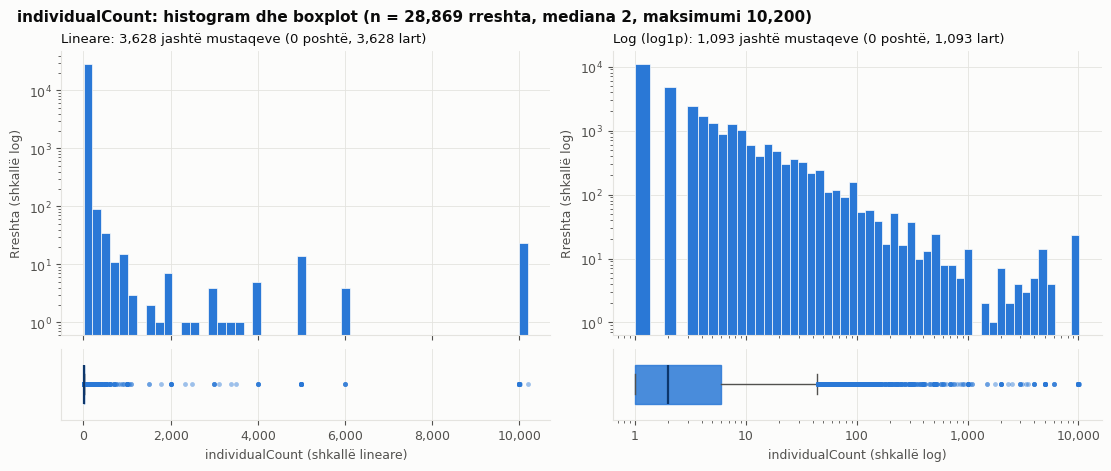

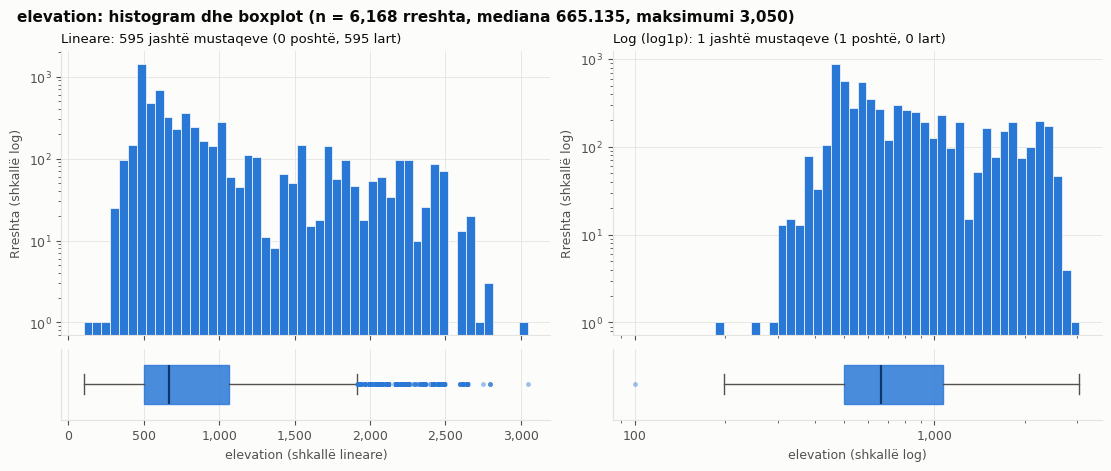

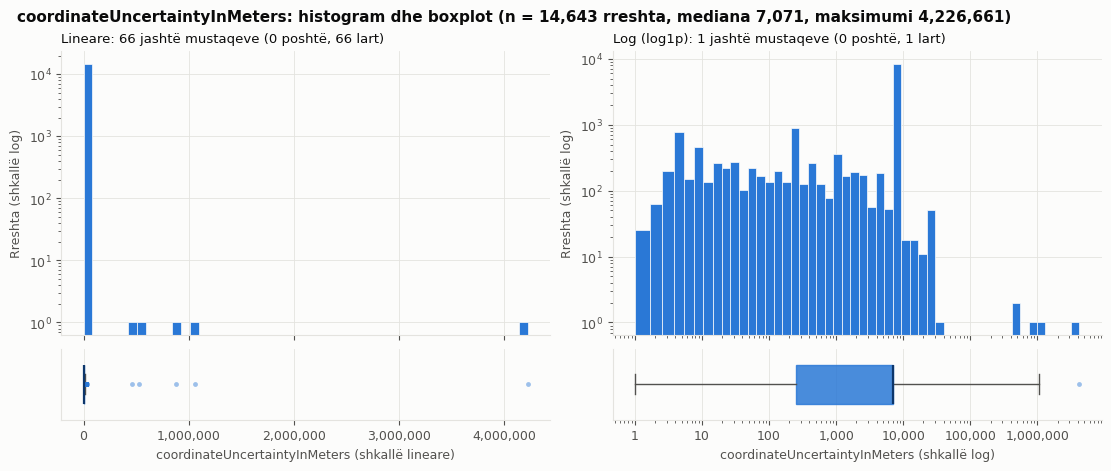

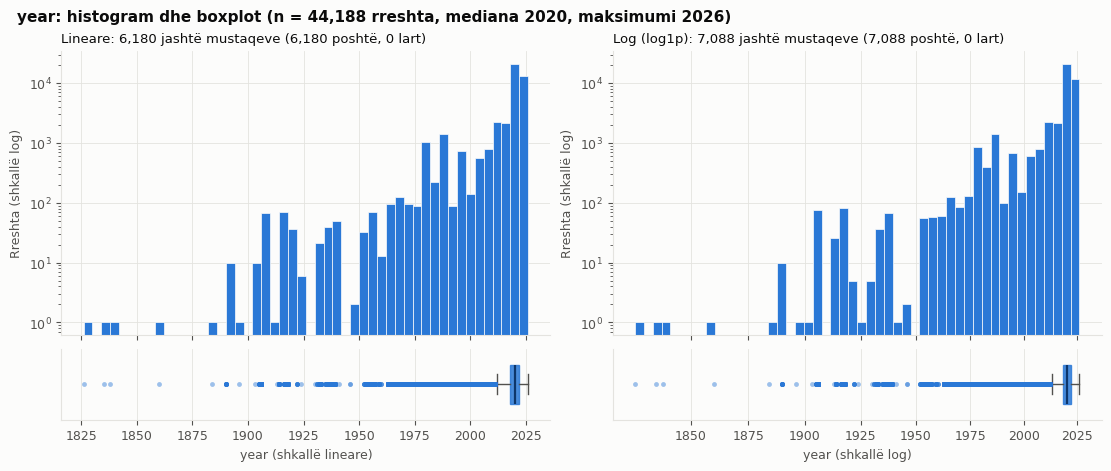

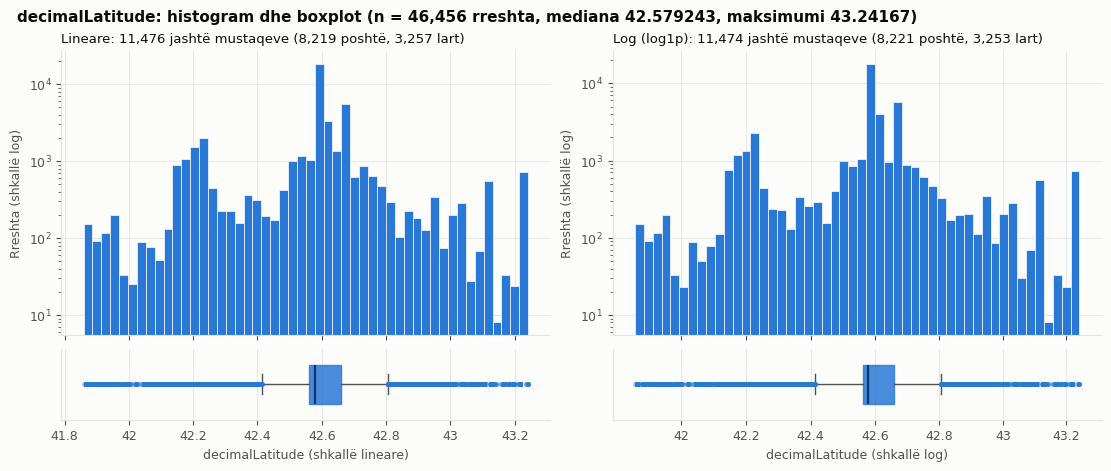

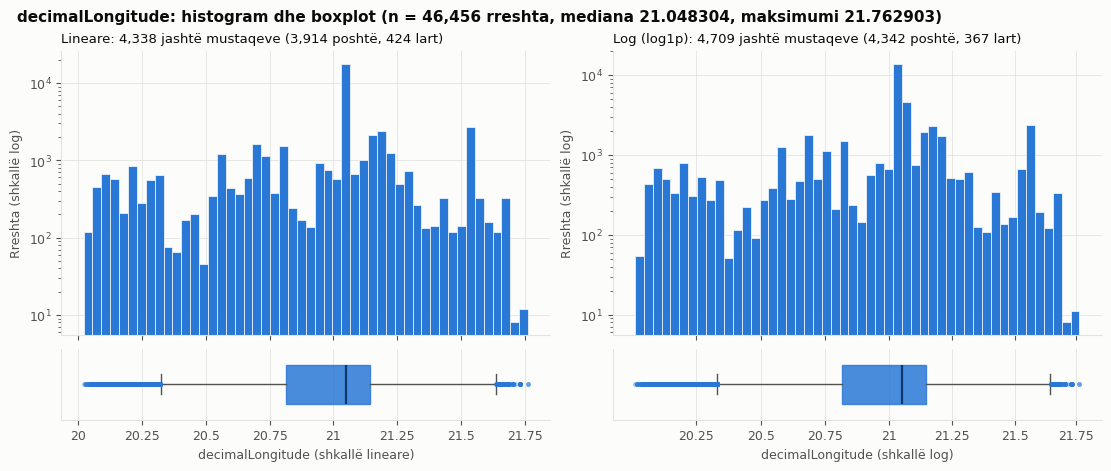

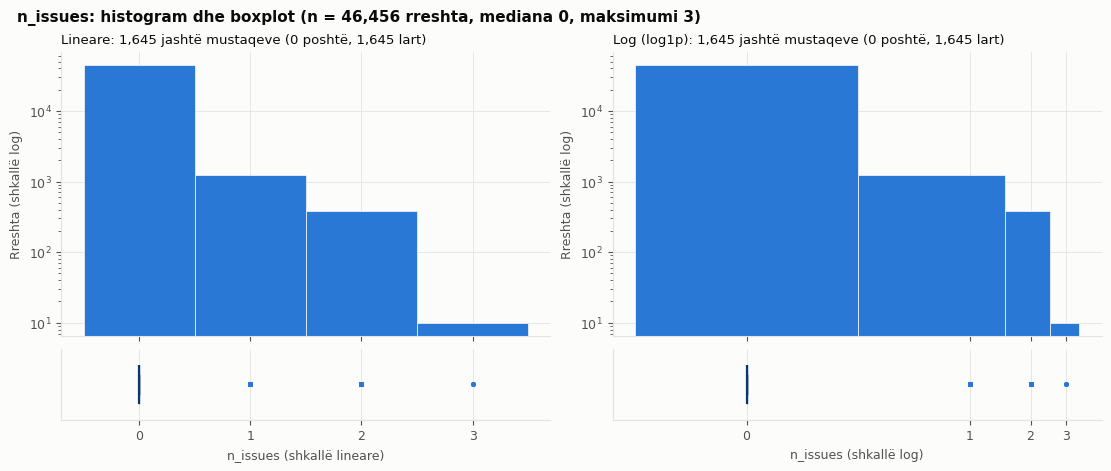

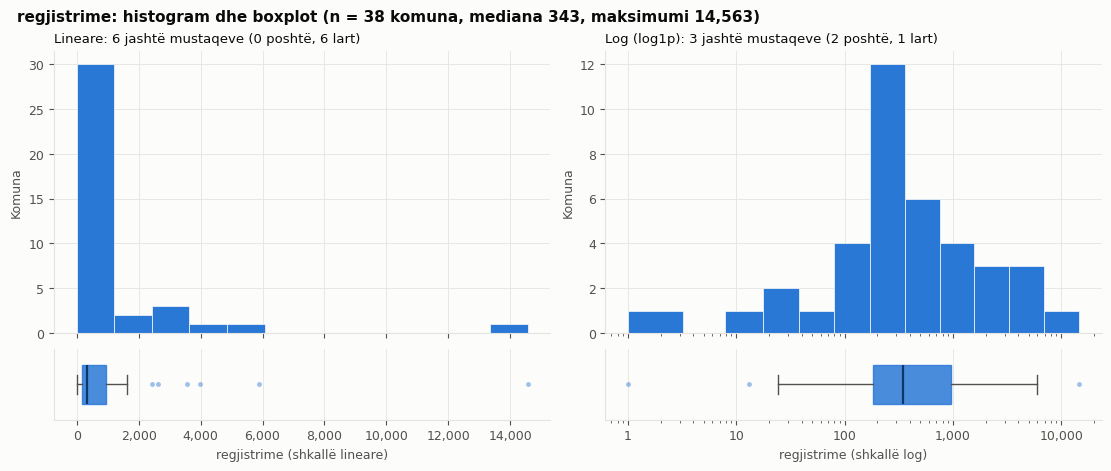

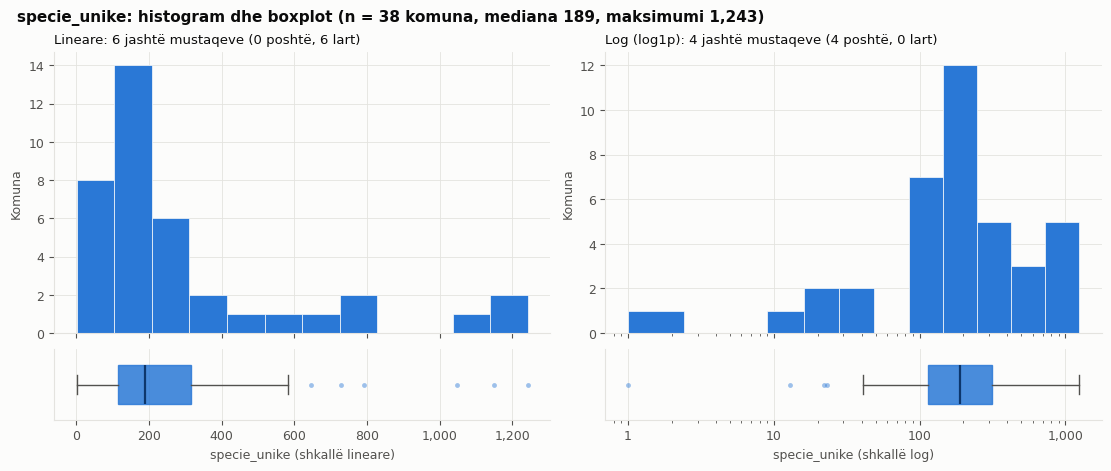

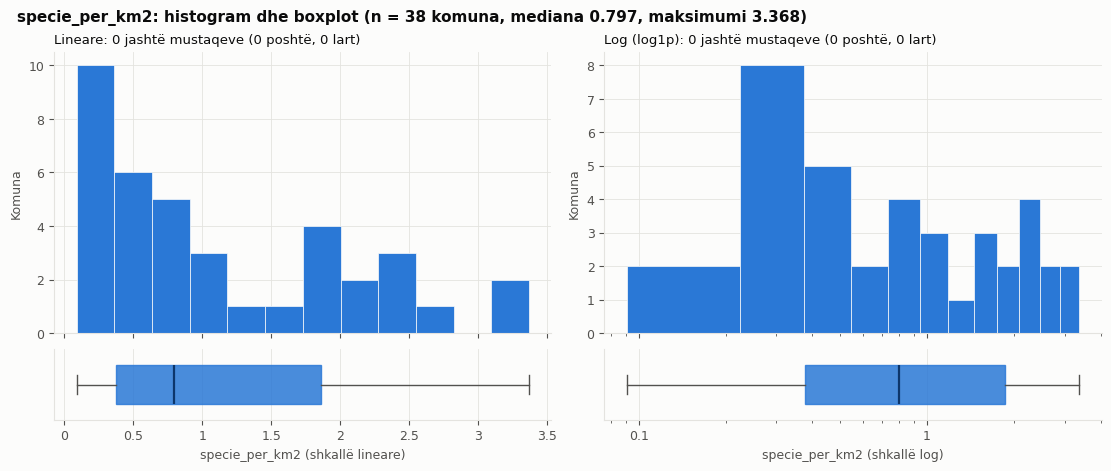

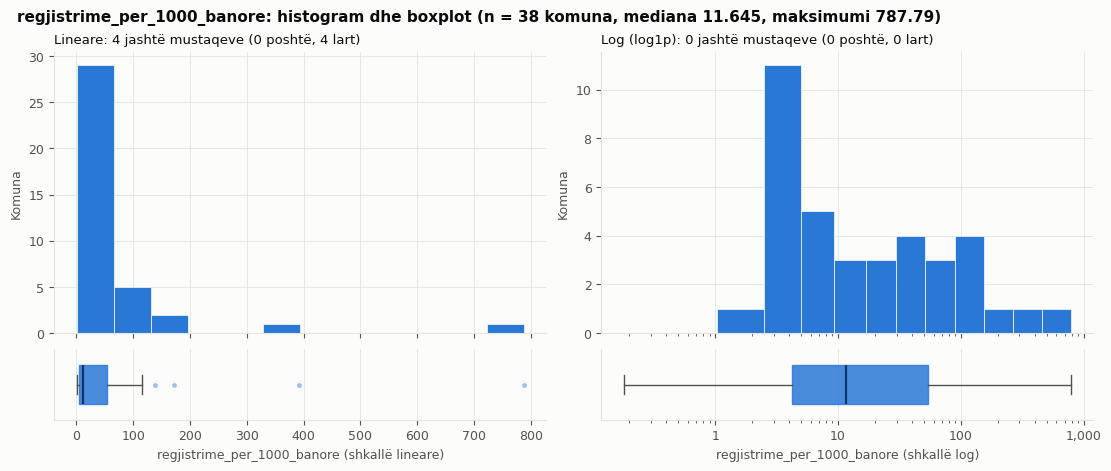

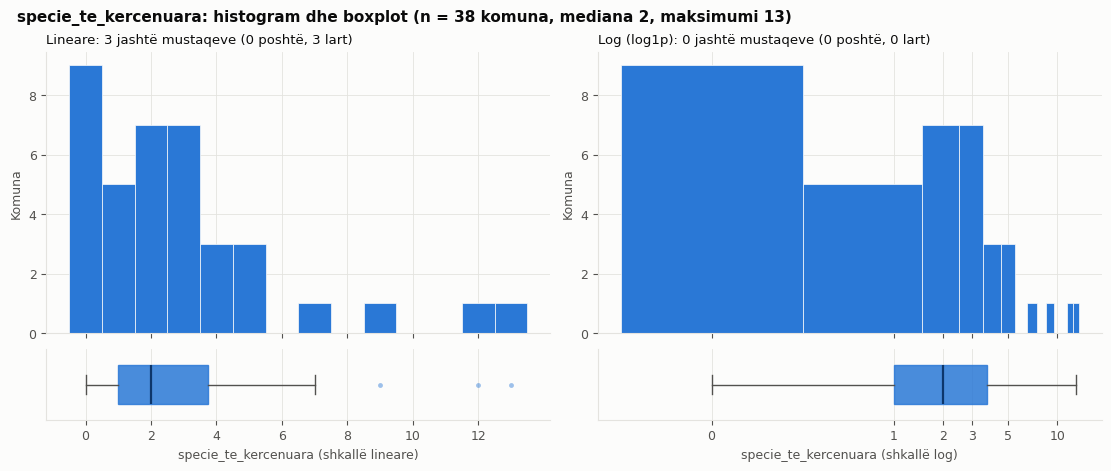

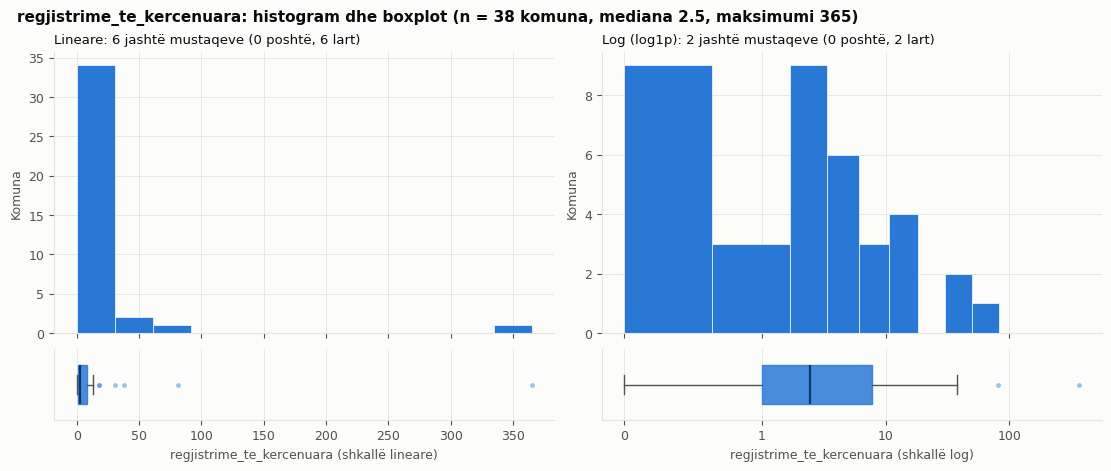

,burimi,kolona,figura,n,jashte_lineare_poshte,jashte_lineare_lart,kufiri_lineare_poshte,kufiri_lineare_lart,jashte_log_poshte,jashte_log_lart,kufiri_log_poshte,kufiri_log_lart
0,rreshta,individualCount,04_vizualizimi_individualCount.png,28869,0,3628,-6.500,13.500,0,1093,-0.695,44.835
1,rreshta,elevation,04_vizualizimi_elevation.png,6168,0,595,-351.956,1914.594,1,0,158.897,3324.593
2,rreshta,coordinateUncertaintyInMeters,04_vizualizimi_coordinateUncertaintyInMeters.png,14643,0,66,-9981.500,17302.500,0,1,0.678,1057656.486
3,rreshta,year,04_vizualizimi_year.png,44188,6180,0,2012.000,2028.000,7088,0,2012.015,2028.015
4,rreshta,decimalLatitude,04_vizualizimi_decimalLatitude.png,46456,8219,3257,42.415,42.806,8221,3253,42.415,42.806
5,rreshta,decimalLongitude,04_vizualizimi_decimalLongitude.png,46456,3914,424,20.323,21.636,4342,367,20.332,21.645
6,rreshta,n_issues,04_vizualizimi_n_issues.png,46456,0,1645,0.000,0.000,0,1645,0.000,0.000
7,komuna,regjistrime,04_vizualizimi_regjistrime.png,38,0,6,-987.375,2129.625,2,1,13.884,11723.480
8,komuna,specie_unike,04_vizualizimi_specie_unike.png,38,0,6,-190.125,620.875,4,0,24.220,1440.993
9,komuna,specie_per_km2,04_vizualizimi_specie_per_km2.png,38,0,0,-1.851,4.088,0,0,-0.541,7.571


In [6]:
import matplotlib.pyplot as plt
from matplotlib import cbook
from matplotlib.ticker import FuncFormatter, NullLocator

BLUE, NAVY, INK, MUTED, GRID, SURFACE = "#2a78d6", "#0d366b", "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "font.size": 9, "axes.titlesize": 9.5, "axes.titlelocation": "left",
})

def box_stats(values, log):
    """Statistikat e boxplot-it; në shkallë log llogariten mbi log1p dhe kthehen në njësi origjinale."""
    t = np.log1p(values) if log else values
    stats = cbook.boxplot_stats(t.to_numpy(dtype=float))[0]
    low, high = iqr_bounds(t)
    n_low, n_high = int((t < low).sum()), int((t > high).sum())
    if log:
        stats = {k: (np.expm1(v) if k in {"med", "q1", "q3", "whislo", "whishi", "fliers"} else v)
                 for k, v in stats.items()}
        low, high = np.expm1(low), np.expm1(high)
    return stats, n_low, n_high, low, high

def is_discrete(values):
    return bool((values % 1 == 0).all() and values.max() - values.min() <= 15)

def bin_edges(values, log, n_bins):
    if is_discrete(values):
        return np.arange(values.min() - 0.5, values.max() + 1.5)
    if log:
        return np.expm1(np.linspace(np.log1p(values.min()), np.log1p(values.max()), n_bins + 1))
    return np.linspace(values.min(), values.max(), n_bins + 1)

def plot_column(frame, column, source):
    values = frame[column].dropna()
    by_row = source == "rreshta"
    fmt = FuncFormatter(lambda x, _: f"{x:.0f}" if column == "year" else format(x, ",.10g"))
    fig, axes = plt.subplots(2, 2, figsize=(11, 4.6), sharex="col", layout="constrained",
                             gridspec_kw={"height_ratios": [4, 1]})
    row = {"burimi": source, "kolona": column, "figura": f"04_vizualizimi_{column}.png", "n": len(values)}
    for j, log in enumerate([False, True]):
        ax_hist, ax_box = axes[0, j], axes[1, j]
        stats, n_low, n_high, low, high = box_stats(values, log)
        ax_hist.hist(values, bins=bin_edges(values, log, 50 if by_row else 12), color=BLUE,
                     edgecolor=SURFACE, linewidth=0.5, log=by_row)
        ax_box.bxp([stats], vert=False, widths=0.55, patch_artist=True,
                   boxprops={"facecolor": BLUE, "edgecolor": BLUE, "alpha": 0.85},
                   medianprops={"color": NAVY, "linewidth": 1.6},
                   whiskerprops={"color": MUTED}, capprops={"color": MUTED},
                   flierprops={"marker": "o", "markersize": 3.5, "markerfacecolor": BLUE,
                               "markeredgecolor": "none", "alpha": 0.45})
        ax_box.set_yticks([])
        ax_box.grid(axis="y", visible=False)
        if log:
            if values.min() > 0:
                ax_box.set_xscale("log")
            else:
                ax_box.set_xscale("symlog", linthresh=1)
            if values.min() > 0 and values.max() / values.min() < 10:   # diapazon i ngushtë: tiket e panelit linear
                ticks = [t for t in axes[1, 0].get_xticks() if values.min() <= t <= values.max()]
                ax_box.set_xticks(ticks)
                ax_box.xaxis.set_minor_locator(NullLocator())
        if is_discrete(values):                                         # tiket te vlerat e plota
            ax_box.set_xticks([t for t in ([0, 1, 2, 3, 5, 10] if log else range(0, 16, 1 if values.max() <= 5 else 2))
                               if values.min() <= t <= values.max()])
            ax_box.xaxis.set_minor_locator(NullLocator())
        ax_box.xaxis.set_major_formatter(fmt)
        ax_box.set_xlabel(f"{column} ({'shkallë log' if log else 'shkallë lineare'})")
        ax_hist.set_ylabel(("Rreshta" if by_row else "Komuna") + (" (shkallë log)" if by_row else ""))
        ax_hist.set_title(f"{'Log (log1p)' if log else 'Lineare'}: "
                          f"{n_low + n_high:,} jashtë mustaqeve ({n_low:,} poshtë, {n_high:,} lart)")
        key = "log" if log else "lineare"
        row |= {f"jashte_{key}_poshte": n_low, f"jashte_{key}_lart": n_high,
                f"kufiri_{key}_poshte": round(low, 3), f"kufiri_{key}_lart": round(high, 3)}
    unit = "rreshta" if by_row else "komuna"
    fig.suptitle(f"{column}: histogram dhe boxplot (n = {len(values):,} {unit}, "
                 f"mediana {format(values.median(), ',.10g') if column != 'year' else int(values.median())}, "
                 f"maksimumi {format(values.max(), ',.10g') if column != 'year' else int(values.max())})",
                 x=0.01, ha="left", fontsize=11, fontweight="bold")
    fig.savefig(FIGURES_DIR / row["figura"], dpi=150)
    plt.show()
    plt.close(fig)
    return row

viz = pd.DataFrame([plot_column(df, c, "rreshta") for c in ROW_COLUMNS]
                   + [plot_column(agg, c, "komuna") for c in AGG_COLUMNS])

# Mustaqet duhet të përputhen me numërimin IQR të seksionit 1.
check = candidate_profile.set_index("kolona")
for r in viz.itertuples():
    assert r.jashte_lineare_poshte + r.jashte_lineare_lart == check.loc[r.kolona, "iqr15_lineare"]
    if r.kolona in LOG_COLUMNS:
        assert r.jashte_log_poshte + r.jashte_log_lart == check.loc[r.kolona, "iqr15_log1p"]
assert len(list(FIGURES_DIR.glob("04_*.png"))) == len(ROW_COLUMNS) + len(AGG_COLUMNS) == 13
display(viz)

### 2.1 Shënimet: çka duket ekstreme në pamje të parë

Shënimet shkruhen nga figurat, me numrat e marrë nga të dhënat. Janë vëzhgime, jo vendime.

In [7]:
v = viz.set_index("kolona")
out = lambda c, key: int(v.loc[c, f"jashte_{key}_poshte"] + v.loc[c, f"jashte_{key}_lart"])

def komunat_jashte(column, log):
    """Emrat e komunave jashtë mustaqeve, nga vlera më e madhe."""
    t = np.log1p(agg[column]) if log else agg[column]
    low, high = iqr_bounds(t)
    hit = agg.loc[(t < low) | (t > high)].sort_values(column, ascending=False)
    return ", ".join(f"{k} ({format(x, ',.10g')})" for k, x in zip(hit["komuna"], hit[column])) or "asnjë"

ic_sorted = np.sort(ic.unique())
cu_sorted = np.sort(cu.unique())
cu_gap = cu_sorted[cu_sorted <= 100_000].max()
el_mode = el.mode().iloc[0]
lat_fl = lat[(lat < v.loc["decimalLatitude", "kufiri_lineare_poshte"]) | (lat > v.loc["decimalLatitude", "kufiri_lineare_lart"])]

NOTES = {
 "individualCount": f"Lineare: e gjithë kutia është te 1–6 dhe nuk shihet; {n(out('individualCount', 'lineare'))} vlera mbi {v.loc['individualCount', 'kufiri_lineare_lart']:.1f} dalin si pika. Log: mbeten {n(out('individualCount', 'log'))} vlera mbi {v.loc['individualCount', 'kufiri_log_lart']:.0f}. Ekstreme duken {n(f['ic_big'])} vlerat ≥ 1,000 dhe sidomos grupi i veçuar 10,000–10,200 ({n(f['ic_10000'])} rreshta), pas një zbrazëtie nga {n(ic_sorted[ic_sorted < 10_000].max())}. Shihen shtylla te numrat e rrumbullakët (2,000, 5,000, 10,000).",
 "elevation": f"Shpërndarje me bisht djathtas dhe një shtyllë të lartë te {n(el_mode)} m ({n(el.eq(el_mode).sum())} rreshta). Lineare: {n(out('elevation', 'lineare'))} vlera mbi {n(v.loc['elevation', 'kufiri_lineare_lart'])} m. Log: mbetet {n(out('elevation', 'log'))} vlerë, nën {n(v.loc['elevation', 'kufiri_log_poshte'])} m, dhe asnjë lart. Ekstreme duken {f['el_hi']} pikat e fundit djathtas ({n(f['el_hi_min'])}–{n(f['el_hi_max'])} m, mbi Gjeravicën) dhe, në shkallë log, {f['el_lo']} vlerat e veçuara majtas ({', '.join(n(x) for x in f['el_lo_values'])} m).",
 "coordinateUncertaintyInMeters": f"Lineare: të gjitha vlerat bien në shtyllën e parë dhe shihen vetëm {f['cu_huge']} pika larg, deri në {n(f['cu_max'])} m. Log: vlerat shtrihen nga 1 m deri {n(cu_gap)} m, me shtylla te 4–5 m (GPS), 250 m dhe sidomos 7,071 m ({n(f['cu_7071'])} rreshta, kod i përgjithësimit). Mediana = Q3 = 7,071, prandaj kutia është e ngushtë. Ekstreme duken {f['cu_huge']} vlerat mbi 100 km, të ndara nga pjesa tjetër me zbrazëti ({n(cu_gap)} → {n(f['cu_huge_min'])} m).",
 "year": f"Bisht i gjatë majtas: kutia është 2018–2022 dhe {n(out('year', 'lineare'))} rreshta para vitit {v.loc['year', 'kufiri_lineare_poshte']:.0f} dalin si pika. Shkalla log nuk ndihmon: diapazoni 1826–2026 është shumë i ngushtë dhe forma mbetet e njëjtë ({n(out('year', 'log'))} jashtë mustaqeve). Ekstreme duken {f['yr_pre1900']} regjistrimet para vitit 1900 (më i vjetri {f['yr_min']}); grupet e viteve 1905–1918 janë të dendura, jo të veçuara. Djathtas nuk ka asgjë pas vitit {f['yr_max']}.",
 "decimalLatitude": f"Një shtyllë e lartë te pika e Henc-it (42.579243, {n(f['ll_top_n'])} rreshta). Ajo e ngushton kutinë, prandaj {n(out('decimalLatitude', 'lineare'))} rreshta dalin jashtë mustaqeve, por janë shpërndarje e vazhdueshme nga {lat_fl.min():.3f} deri {lat_fl.max():.3f}, brenda Kosovës. Asnjë pikë e veçuar nuk shihet. Shkalla log nuk ndihmon: forma mbetet e njëjtë.",
 "decimalLongitude": f"E njëjta pamje: shtyllë te 21.048304 (Henc) dhe {n(out('decimalLongitude', 'lineare'))} rreshta jashtë mustaqeve, {n(v.loc['decimalLongitude', 'jashte_lineare_poshte'])} në perëndim dhe {n(v.loc['decimalLongitude', 'jashte_lineare_lart'])} në lindje. Vlerat mbeten brenda kutisë 20.01–21.80, pa pika të veçuara. Për koordinatat duhet pamje 2D (distanca te fqinjët), jo boxplot.",
 "n_issues": f"Katër shtylla diskrete: 0 ({n(f['ni_counts'][0])}), 1 ({n(f['ni_counts'][1])}), 2 ({n(f['ni_counts'][2])}), 3 ({n(f['ni_counts'][3])}). Kutia është vijë te 0, prandaj çdo rresht me ≥ 1 flamur ({n(f['ni_ge1'])}) del si pikë, në të dy shkallët. Të rralla duken vetëm {f['ni_3']} rreshtat me 3 flamuj.",
 "regjistrime": f"Lineare: {komunat_jashte('regjistrime', False)} dalin jashtë mustaqeve; Graçanica është shumë larg të tjerave. Log: {komunat_jashte('regjistrime', True)}. Në log shfaqet edhe skaji i poshtëm (Mamushë me 1 regjistrim), që në lineare nuk shihet.",
 "specie_unike": f"Lineare: {komunat_jashte('specie_unike', False)}. Log: {komunat_jashte('specie_unike', True)}. Skaji i sipërm pas log nuk duket më ekstrem; mbeten komunat me shumë pak specie.",
 "specie_per_km2": f"Asnjë komunë jashtë mustaqeve, as në lineare as në log. Bishti djathtas (Junik {agg.set_index('komuna').loc['Junik', 'specie_per_km2']}, Ranillug {agg.set_index('komuna').loc['Ranillug', 'specie_per_km2']}) është i vazhdueshëm. Asgjë nuk duket ekstreme.",
 "regjistrime_per_1000_banore": f"Lineare: {komunat_jashte('regjistrime_per_1000_banore', False)}. Graçanica është e ndarë qartë nga të tjerat. Log: {komunat_jashte('regjistrime_per_1000_banore', True)}; shpërndarja bëhet afërsisht simetrike.",
 "specie_te_kercenuara": f"Vlera diskrete 0–13, {f['agg_no_threat']} komuna me 0. Lineare: {komunat_jashte('specie_te_kercenuara', False)}. Log: {komunat_jashte('specie_te_kercenuara', True)}. Bishti është i vazhdueshëm, pa zbrazëti.",
 "regjistrime_te_kercenuara": f"Lineare: {komunat_jashte('regjistrime_te_kercenuara', False)}. Log: {komunat_jashte('regjistrime_te_kercenuara', True)}. Graçanica (365) është e veçuar në të dy shkallët, shumë larg të dytës.",
}
assert set(NOTES) == set(viz["kolona"])

viz["pamja_e_pare"] = viz["kolona"].map(NOTES)
viz.to_csv(REPORTS_DIR / "04_vizualizimi_shenimet.csv", index=False)

notes_table = to_markdown(pd.DataFrame({
    "Kolona": "`" + viz["kolona"] + "`" + np.where(viz["burimi"].eq("komuna"), " (komuna)", ""),
    "Figura": "`reports/figures/" + viz["figura"] + "`",
    "Jashtë mustaqeve (lineare)": viz[["jashte_lineare_poshte", "jashte_lineare_lart"]].sum(axis=1).map(n),
    "Jashtë mustaqeve (log)": viz[["jashte_log_poshte", "jashte_log_lart"]].sum(axis=1).map(n),
    "Çka duket ekstreme në pamje të parë": viz["pamja_e_pare"],
}))
display(Markdown(notes_table))

| Kolona | Figura | Jashtë mustaqeve (lineare) | Jashtë mustaqeve (log) | Çka duket ekstreme në pamje të parë |
|---|---|---|---|---|
| `individualCount` | `reports/figures/04_vizualizimi_individualCount.png` | 3,628 | 1,093 | Lineare: e gjithë kutia është te 1–6 dhe nuk shihet; 3,628 vlera mbi 13.5 dalin si pika. Log: mbeten 1,093 vlera mbi 45. Ekstreme duken 79 vlerat ≥ 1,000 dhe sidomos grupi i veçuar 10,000–10,200 (23 rreshta), pas një zbrazëtie nga 6,000. Shihen shtylla te numrat e rrumbullakët (2,000, 5,000, 10,000). |
| `elevation` | `reports/figures/04_vizualizimi_elevation.png` | 595 | 1 | Shpërndarje me bisht djathtas dhe një shtyllë të lartë te 481 m (749 rreshta). Lineare: 595 vlera mbi 1,915 m. Log: mbetet 1 vlerë, nën 159 m, dhe asnjë lart. Ekstreme duken 5 pikat e fundit djathtas (2,750–3,050 m, mbi Gjeravicën) dhe, në shkallë log, 4 vlerat e veçuara majtas (100, 198, 250, 293 m). |
| `coordinateUncertaintyInMeters` | `reports/figures/04_vizualizimi_coordinateUncertaintyInMeters.png` | 66 | 1 | Lineare: të gjitha vlerat bien në shtyllën e parë dhe shihen vetëm 5 pika larg, deri në 4,226,661 m. Log: vlerat shtrihen nga 1 m deri 32,112 m, me shtylla te 4–5 m (GPS), 250 m dhe sidomos 7,071 m (8,225 rreshta, kod i përgjithësimit). Mediana = Q3 = 7,071, prandaj kutia është e ngushtë. Ekstreme duken 5 vlerat mbi 100 km, të ndara nga pjesa tjetër me zbrazëti (32,112 → 462,462 m). |
| `year` | `reports/figures/04_vizualizimi_year.png` | 6,180 | 7,088 | Bisht i gjatë majtas: kutia është 2018–2022 dhe 6,180 rreshta para vitit 2012 dalin si pika. Shkalla log nuk ndihmon: diapazoni 1826–2026 është shumë i ngushtë dhe forma mbetet e njëjtë (7,088 jashtë mustaqeve). Ekstreme duken 16 regjistrimet para vitit 1900 (më i vjetri 1826); grupet e viteve 1905–1918 janë të dendura, jo të veçuara. Djathtas nuk ka asgjë pas vitit 2026. |
| `decimalLatitude` | `reports/figures/04_vizualizimi_decimalLatitude.png` | 11,476 | 11,474 | Një shtyllë e lartë te pika e Henc-it (42.579243, 12,943 rreshta). Ajo e ngushton kutinë, prandaj 11,476 rreshta dalin jashtë mustaqeve, por janë shpërndarje e vazhdueshme nga 41.859 deri 43.242, brenda Kosovës. Asnjë pikë e veçuar nuk shihet. Shkalla log nuk ndihmon: forma mbetet e njëjtë. |
| `decimalLongitude` | `reports/figures/04_vizualizimi_decimalLongitude.png` | 4,338 | 4,709 | E njëjta pamje: shtyllë te 21.048304 (Henc) dhe 4,338 rreshta jashtë mustaqeve, 3,914 në perëndim dhe 424 në lindje. Vlerat mbeten brenda kutisë 20.01–21.80, pa pika të veçuara. Për koordinatat duhet pamje 2D (distanca te fqinjët), jo boxplot. |
| `n_issues` | `reports/figures/04_vizualizimi_n_issues.png` | 1,645 | 1,645 | Katër shtylla diskrete: 0 (44,811), 1 (1,251), 2 (384), 3 (10). Kutia është vijë te 0, prandaj çdo rresht me ≥ 1 flamur (1,645) del si pikë, në të dy shkallët. Të rralla duken vetëm 10 rreshtat me 3 flamuj. |
| `regjistrime` (komuna) | `reports/figures/04_vizualizimi_regjistrime.png` | 6 | 3 | Lineare: Graçanicë (14,563), Prishtinë (5,893), Prizren (3,969), Fushë Kosovë (3,562), Kamenicë (2,616), Pejë (2,443) dalin jashtë mustaqeve; Graçanica është shumë larg të tjerave. Log: Graçanicë (14,563), Kllokot (13), Mamushë (1). Në log shfaqet edhe skaji i poshtëm (Mamushë me 1 regjistrim), që në lineare nuk shihet. |
| `specie_unike` (komuna) | `reports/figures/04_vizualizimi_specie_unike.png` | 6 | 4 | Lineare: Prizren (1,243), Prishtinë (1,149), Pejë (1,049), Kamenicë (792), Deçan (729), Leposaviq (647). Log: Partesh (23), Mitrovicë e Veriut (22), Kllokot (13), Mamushë (1). Skaji i sipërm pas log nuk duket më ekstrem; mbeten komunat me shumë pak specie. |
| `specie_per_km2` (komuna) | `reports/figures/04_vizualizimi_specie_per_km2.png` | 0 | 0 | Asnjë komunë jashtë mustaqeve, as në lineare as në log. Bishti djathtas (Junik 3.368, Ranillug 3.182) është i vazhdueshëm. Asgjë nuk duket ekstreme. |
| `regjistrime_per_1000_banore` (komuna) | `reports/figures/04_vizualizimi_regjistrime_per_1000_banore.png` | 4 | 0 | Lineare: Graçanicë (787.79), Ranillug (392.18), Leposaviq (171.32), Junik (138.98). Graçanica është e ndarë qartë nga të tjerat. Log: asnjë; shpërndarja bëhet afërsisht simetrike. |
| `specie_te_kercenuara` (komuna) | `reports/figures/04_vizualizimi_specie_te_kercenuara.png` | 3 | 0 | Vlera diskrete 0–13, 9 komuna me 0. Lineare: Prishtinë (13), Prizren (12), Pejë (9). Log: asnjë. Bishti është i vazhdueshëm, pa zbrazëti. |
| `regjistrime_te_kercenuara` (komuna) | `reports/figures/04_vizualizimi_regjistrime_te_kercenuara.png` | 6 | 2 | Lineare: Graçanicë (365), Fushë Kosovë (81), Prishtinë (38), Prizren (31), Pejë (18), Shtërpcë (18). Log: Graçanicë (365), Fushë Kosovë (81). Graçanica (365) është e veçuar në të dy shkallët, shumë larg të dytës. |

In [8]:
viz_report = f"""# Vizualizimi fillestar i kolonave kandidate

**Versioni:** 1.0
**Data:** 19.11.2026
**Statusi:** Pamje e parë. Asnjë vlerë nuk shënohet ose fshihet. IQR zbatohet më 20 nëntor.

## Si lexohen figurat

Çdo kolonë kandidate ka një figurë te `reports/figures/04_vizualizimi_<kolona>.png` (13 figura). Majtas është shkalla lineare, djathtas shkalla log. Sipër është histogrami, poshtë boxplot-i me të njëjtin bosht.

- Mustaqet janë Q1 − 1.5·IQR dhe Q3 + 1.5·IQR. Në panelin log llogariten mbi `log1p(x)` dhe boshti tregon vlerat origjinale. Kolonat me zero (`n_issues`, `specie_te_kercenuara`, `regjistrime_te_kercenuara`) kanë bosht `symlog`.
- Te kolonat në nivel rreshti boshti i numrit të rreshtave është log, që të shihen edhe shtyllat me 1–10 rreshta. Te komunat (38) është linear.
- Numrat e pikave jashtë mustaqeve përputhen me `reports/04_kolonat_kandidate.csv`.

## Shënimet

{notes_table}

## Përmbledhje

- **Shkalla log ndihmon te kolonat e anuara.** Te `individualCount` pikat jashtë mustaqeve bien nga {n(out('individualCount', 'lineare'))} në {n(out('individualCount', 'log'))}, te `coordinateUncertaintyInMeters` nga {n(out('coordinateUncertaintyInMeters', 'lineare'))} në {n(out('coordinateUncertaintyInMeters', 'log'))}, te `regjistrime` nga {out('regjistrime', 'lineare')} në {out('regjistrime', 'log')} komuna.
- **Vlerat që duken vërtet të veçuara** (pas një zbrazëtie): `individualCount` 10,000–10,200 ({n(f['ic_10000'])} rreshta), `coordinateUncertaintyInMeters` mbi 100 km ({f['cu_huge']}), `elevation` mbi {n(ELEV_MAX)} m ({f['el_hi']}) dhe nën {ELEV_MIN} m ({f['el_lo']}), `year` para 1900 ({f['yr_pre1900']}), dhe Graçanica te agregatet e komunave.
- **Boxplot-i mashtron te `year`, koordinatat dhe `n_issues`.** Pikat jashtë mustaqeve atje ({n(out('year', 'lineare'))}, {n(out('decimalLatitude', 'lineare'))}, {n(out('decimalLongitude', 'lineare'))}, {n(out('n_issues', 'lineare'))}) vijnë nga kutia e ngushtë (eBird 2018–2022, pika e Henc-it, Q1 = Q3 = 0), jo nga vlera të veçuara. Shkalla log nuk ndihmon te këto kolona: forma mbetet e njëjtë.
- Pamja përputhet me planin e 18 nëntorit: `log1p` për kolonat e anuara, metoda kontekstuale për lartësinë dhe vitin, metoda hapësinore për koordinatat.

## Dokumentimi i detyrës

- **Input:** `processed/biodiversity_features.csv` ({f['N']:,} rreshta, 7 kolona) dhe `processed/agg_municipality_v2.csv` (38 komuna, 6 kolona).
- **Çka u bë:** Për secilën nga 13 kolonat kandidate u vizatua histogram dhe boxplot në shkallë lineare dhe log, dhe u shënua çka duket ekstreme në pamje të parë.
- **Rreshta para / pas:** {f['N']:,} / {f['N']:,}. Asnjë vlerë nuk u shënua ose u ndryshua.
- **Pse u bë:** Që para metodave statistikore të shihet forma e çdo shpërndarjeje dhe cila shkallë i përshtatet secilës kolonë.
- **Output:** `reports/figures/04_vizualizimi_*.png` (13 figura), `reports/perjashtuesit_vizualizimi.md`, `reports/04_vizualizimi_shenimet.csv`, seksioni 2 i `notebooks/04_perjashtuesit.ipynb`.
- **Commit:** `Dafina: vizualizimi fillestar i kolonave kandidate`.
"""
(REPORTS_DIR / "perjashtuesit_vizualizimi.md").write_text(viz_report, encoding="utf-8")
print("U ruajt:", REPORTS_DIR / "perjashtuesit_vizualizimi.md")

U ruajt: c:\Master\PVDH\reports\perjashtuesit_vizualizimi.md


### Dokumentimi i detyrës (19 nëntor)

1. **Input:** `processed/biodiversity_features.csv` (46,456 rreshta, 7 kolona) dhe `processed/agg_municipality_v2.csv` (38 komuna, 6 kolona).
2. **Çka u bë:** Për secilën nga 13 kolonat kandidate u vizatua histogram dhe boxplot në shkallë lineare dhe log. U shënua çka duket ekstreme në pamje të parë.
3. **Rreshta para / pas:** 46,456 / 46,456. Asnjë vlerë nuk u shënua ose u ndryshua.
4. **Pse u bë:** Që para metodave statistikore të shihet forma e çdo shpërndarjeje dhe cila shkallë i përshtatet secilës kolonë.
5. **Output:** `reports/figures/04_vizualizimi_*.png` (13 figura), shënimet te `reports/perjashtuesit_vizualizimi.md` dhe `reports/04_vizualizimi_shenimet.csv`.
6. **Commit:** `Dafina: vizualizimi fillestar i kolonave kandidate`.

## 3. Metoda IQR (20 nëntor)

Për secilën kolonë kandidate llogariten kufijtë **Q1 − k·IQR** dhe **Q3 + k·IQR** me **k = 1.5** dhe **k = 3**. Vlera jashtë kufijve numërohet si përjashtues i mundshëm.

- **Shkalla log:** për kolonat e anuara (skewness > 1 në shkallë lineare) kufijtë llogariten edhe mbi `log1p(x)` dhe kthehen në njësi origjinale me `expm1`. Kufiri i poshtëm negativ do të thotë se në praktikë nuk ka kufi të poshtëm.
- **%** llogaritet mbi vlerat e plotësuara të kolonës, jo mbi 46,456 rreshtat.
- Asnjë vlerë nuk fshihet. Në fund zgjidhet një k dhe një shkallë për kolonë, dhe vetëm ai kombinim bëhet flamur 0/1.

### 3.1 Kufijtë, numri dhe % i përjashtuesve

Kolonat e anuara dalin nga skewness, jo nga lista paraprake e 18 nëntorit: shtohen `elevation` dhe `n_issues`, del `specie_per_km2`.

In [9]:
K_VALUES = (1.5, 3)
SKEW_LIMIT = 1                                   # skewness > 1: kolonë e anuar djathtas
FRAMES = {"rreshta": df, "komuna": agg}
CANDIDATES = [("rreshta", c) for c in ROW_COLUMNS] + [("komuna", c) for c in AGG_COLUMNS]

skew_tab = pd.DataFrame([{"burimi": s, "kolona": c,
                          "skewness_lineare": FRAMES[s][c].skew(),
                          "skewness_log1p": np.log1p(FRAMES[s][c]).skew()} for s, c in CANDIDATES])
skew_tab["e_anuar"] = skew_tab["skewness_lineare"] > SKEW_LIMIT
SKEWED_COLUMNS = set(skew_tab.loc[skew_tab["e_anuar"], "kolona"])
assert SKEWED_COLUMNS == (LOG_COLUMNS | {"elevation", "n_issues"}) - {"specie_per_km2"}

def iqr_mask(frame, column, log, k):
    """True te vlerat jashtë kufijve. Vlerat që mungojnë nuk shënohen."""
    t = np.log1p(frame[column]) if log else frame[column]
    low, high = iqr_bounds(t.dropna(), k)
    return (t < low) | (t > high)

def iqr_row(source, column, log, k):
    values = FRAMES[source][column].dropna()
    t = np.log1p(values) if log else values
    low, high = iqr_bounds(t, k)
    n_low, n_high = int((t < low).sum()), int((t > high).sum())
    if log:                                      # kufijtë kthehen në njësi origjinale
        low, high = np.expm1(low), np.expm1(high)
    return {"burimi": source, "kolona": column, "shkalla": "log1p" if log else "lineare", "k": k,
            "n_vlera": len(values), "kufiri_poshte": low, "kufiri_lart": high,
            "n_poshte": n_low, "n_lart": n_high, "n": n_low + n_high,
            "pct": (n_low + n_high) / len(values) * 100}

iqr = pd.DataFrame([iqr_row(s, c, log, k) for s, c in CANDIDATES for log in (False, True) for k in K_VALUES
                    if not log or c in SKEWED_COLUMNS])

# k = 1.5 duhet të përputhet me numërimin e seksionit 1.
profile_15 = candidate_profile.set_index("kolona")
for r in iqr[iqr["k"].eq(1.5)].itertuples():
    expected = profile_15.loc[r.kolona, "iqr15_lineare" if r.shkalla == "lineare" else "iqr15_log1p"]
    assert pd.isna(expected) or r.n == expected

def fmt_value(column, x):
    if column == "year":
        return f"{x:.0f}"
    if column in {"decimalLatitude", "decimalLongitude", "specie_per_km2"}:
        return f"{x:.3f}"
    return f"{x:,.1f}"

label = lambda r: f"`{r.kolona}`" + (" (komuna)" if r.burimi == "komuna" else "")
iqr["kufijte"] = [f"[{fmt_value(r.kolona, r.kufiri_poshte)}, {fmt_value(r.kolona, r.kufiri_lart)}]"
                  for r in iqr.itertuples()]

skew_table = to_markdown(pd.DataFrame({
    "Kolona": [label(r) for r in skew_tab.itertuples()],
    "Skewness (lineare)": skew_tab["skewness_lineare"].map("{:.2f}".format),
    "Skewness (log1p)": np.where(skew_tab["e_anuar"], skew_tab["skewness_log1p"].map("{:.2f}".format), "—"),
    "E anuar (> 1)": np.where(skew_tab["e_anuar"], "po", "jo"),
}))

def side_by_side(table):
    """Kolona | k | Kufijtë | n | %, lineare dhe log krah për krah."""
    log_rows = table[table["shkalla"].eq("log1p")].set_index(["kolona", "k"])
    rows = []
    for r in table[table["shkalla"].eq("lineare")].itertuples():
        g = log_rows.loc[(r.kolona, r.k)] if (r.kolona, r.k) in log_rows.index else None
        rows.append({"Kolona": label(r), "k": f"{r.k:g}",
                     "Kufijtë (lineare)": r.kufijte, "n (lineare)": n(r.n), "% (lineare)": f"{r.pct:.2f}",
                     "Kufijtë (log1p)": g["kufijte"] if g is not None else "—",
                     "n (log1p)": n(g["n"]) if g is not None else "—",
                     "% (log1p)": f"{g['pct']:.2f}" if g is not None else "—"})
    return pd.DataFrame(rows)

iqr_table = to_markdown(side_by_side(iqr))
display(Markdown(skew_table))
display(Markdown(iqr_table))

| Kolona | Skewness (lineare) | Skewness (log1p) | E anuar (> 1) |
|---|---|---|---|
| `individualCount` | 26.63 | 2.07 | po |
| `elevation` | 1.39 | 0.74 | po |
| `coordinateUncertaintyInMeters` | 101.73 | -1.00 | po |
| `year` | -3.77 | — | jo |
| `decimalLatitude` | -0.12 | — | jo |
| `decimalLongitude` | -0.75 | — | jo |
| `n_issues` | 6.18 | 5.49 | po |
| `regjistrime` (komuna) | 4.25 | -0.64 | po |
| `specie_unike` (komuna) | 1.76 | -1.22 | po |
| `specie_per_km2` (komuna) | 0.87 | — | jo |
| `regjistrime_per_1000_banore` (komuna) | 4.22 | 0.58 | po |
| `specie_te_kercenuara` (komuna) | 1.84 | 0.04 | po |
| `regjistrime_te_kercenuara` (komuna) | 5.64 | 1.15 | po |

| Kolona | k | Kufijtë (lineare) | n (lineare) | % (lineare) | Kufijtë (log1p) | n (log1p) | % (log1p) |
|---|---|---|---|---|---|---|---|
| `individualCount` | 1.5 | [-6.5, 13.5] | 3,628 | 12.57 | [-0.7, 44.8] | 1,093 | 3.79 |
| `individualCount` | 3 | [-14.0, 21.0] | 2,258 | 7.82 | [-1.0, 299.1] | 180 | 0.62 |
| `elevation` | 1.5 | [-352.0, 1,914.6] | 595 | 9.65 | [158.9, 3,324.6] | 1 | 0.02 |
| `elevation` | 3 | [-1,201.9, 2,764.6] | 4 | 0.06 | [50.2, 10,377.4] | 0 | 0.00 |
| `coordinateUncertaintyInMeters` | 1.5 | [-9,981.5, 17,302.5] | 66 | 0.45 | [0.7, 1,057,656.5] | 1 | 0.01 |
| `coordinateUncertaintyInMeters` | 3 | [-20,213.0, 27,534.0] | 54 | 0.37 | [-1.0, 158,178,641.3] | 0 | 0.00 |
| `year` | 1.5 | [2012, 2028] | 6,180 | 13.99 | — | — | — |
| `year` | 3 | [2006, 2034] | 5,044 | 11.41 | — | — | — |
| `decimalLatitude` | 1.5 | [42.415, 42.806] | 11,476 | 24.70 | — | — | — |
| `decimalLatitude` | 3 | [42.268, 42.952] | 8,929 | 19.22 | — | — | — |
| `decimalLongitude` | 1.5 | [20.323, 21.636] | 4,338 | 9.34 | — | — | — |
| `decimalLongitude` | 3 | [19.830, 22.129] | 0 | 0.00 | — | — | — |
| `n_issues` | 1.5 | [0.0, 0.0] | 1,645 | 3.54 | [0.0, 0.0] | 1,645 | 3.54 |
| `n_issues` | 3 | [0.0, 0.0] | 1,645 | 3.54 | [0.0, 0.0] | 1,645 | 3.54 |
| `regjistrime` (komuna) | 1.5 | [-987.4, 2,129.6] | 6 | 15.79 | [13.9, 11,723.5] | 3 | 7.89 |
| `regjistrime` (komuna) | 3 | [-2,156.2, 3,298.5] | 4 | 10.53 | [0.2, 142,964.9] | 0 | 0.00 |
| `specie_unike` (komuna) | 1.5 | [-190.1, 620.9] | 6 | 15.79 | [24.2, 1,441.0] | 4 | 10.53 |
| `specie_unike` (komuna) | 3 | [-494.2, 925.0] | 3 | 7.89 | [4.5, 6,574.4] | 1 | 2.63 |
| `specie_per_km2` (komuna) | 1.5 | [-1.851, 4.088] | 0 | 0.00 | — | — | — |
| `specie_per_km2` (komuna) | 3 | [-4.078, 6.315] | 0 | 0.00 | — | — | — |
| `regjistrime_per_1000_banore` (komuna) | 1.5 | [-71.1, 129.6] | 4 | 10.53 | [-0.9, 1,925.4] | 0 | 0.00 |
| `regjistrime_per_1000_banore` (komuna) | 3 | [-146.4, 204.9] | 2 | 5.26 | [-1.0, 67,086.1] | 0 | 0.00 |
| `specie_te_kercenuara` (komuna) | 1.5 | [-3.1, 7.9] | 3 | 7.89 | [-0.4, 16.2] | 0 | 0.00 |
| `specie_te_kercenuara` (komuna) | 3 | [-7.2, 12.0] | 1 | 2.63 | [-0.8, 61.5] | 0 | 0.00 |
| `regjistrime_te_kercenuara` (komuna) | 1.5 | [-9.1, 17.9] | 6 | 15.79 | [-0.8, 78.8] | 2 | 5.26 |
| `regjistrime_te_kercenuara` (komuna) | 3 | [-19.2, 28.0] | 4 | 10.53 | [-1.0, 728.0] | 0 | 0.00 |

### 3.2 Kontrolli kundrejt vlerave të njohura

Vlerat e njohura vijnë nga plani i 18 nëntorit dhe nga figurat e 19 nëntorit: tufat me ≥ 1,000 individë, kufijtë fizikë të lartësisë dhe pasiguria mbi 100 km. Tabela tregon sa prej tyre i kap secili kombinim i shkallës dhe k-së.

In [10]:
REFERENCE = [
    ("individualCount", "≥ 1,000 individë", df["individualCount"] >= 1_000),
    ("elevation", f"> {ELEV_MAX:,} m (mbi Gjeravicën)", df["elevation"] > ELEV_MAX),
    ("elevation", f"< {ELEV_MIN} m", df["elevation"] < ELEV_MIN),
    ("coordinateUncertaintyInMeters", "> 100 km", df["coordinateUncertaintyInMeters"] > 100_000),
]
VARIANTS = [(False, 1.5), (False, 3), (True, 1.5), (True, 3)]

reference_rows = []
for column, case, known in REFERENCE:
    entry = {"Kolona": f"`{column}`", "Vlerat e njohura": case, "Gjithsej": int(known.sum())}
    for log, k in VARIANTS:
        entry[f"{'log1p' if log else 'lineare'}, k = {k:g}"] = int((iqr_mask(df, column, log, k) & known).sum())
    reference_rows.append(entry)
reference_tab = pd.DataFrame(reference_rows)
reference_table = to_markdown(reference_tab)
display(Markdown(reference_table))

| Kolona | Vlerat e njohura | Gjithsej | lineare, k = 1.5 | lineare, k = 3 | log1p, k = 1.5 | log1p, k = 3 |
|---|---|---|---|---|---|---|
| `individualCount` | ≥ 1,000 individë | 79 | 79 | 79 | 79 | 79 |
| `elevation` | > 2,656 m (mbi Gjeravicën) | 5 | 5 | 4 | 0 | 0 |
| `elevation` | < 297 m | 4 | 0 | 0 | 1 | 0 |
| `coordinateUncertaintyInMeters` | > 100 km | 5 | 5 | 5 | 1 | 0 |

### 3.3 Vendimi: cili k dhe cila shkallë mbahet

Për secilën kolonë mbahet një kombinim. Ku IQR globale nuk është e përdorshme, nuk mbahet asnjë dhe kolona u lihet metodave tjera të planit.

In [11]:
IC, EL, CU, YR = "individualCount", "elevation", "coordinateUncertaintyInMeters", "year"
LAT, LON, NI = "decimalLatitude", "decimalLongitude", "n_issues"
RG, SU, SK2, RB, ST, RT = AGG_COLUMNS

KEEP = {  # kolona: (shkalla, k), ose None kur IQR globale nuk mbahet
    IC: ("log1p", 3), EL: ("lineare", 3), CU: ("lineare", 3),
    YR: None, LAT: None, LON: None, NI: None,
    RG: ("log1p", 1.5), SU: ("log1p", 1.5), SK2: ("lineare", 1.5),
    RB: ("log1p", 1.5), ST: ("log1p", 1.5), RT: ("log1p", 1.5),
}
assert set(KEEP) == {c for _, c in CANDIDATES}
assert all(keep is None or keep[0] == "lineare" or c in SKEWED_COLUMNS for c, keep in KEEP.items())

# Flamujt 0/1 të kombinimit të mbajtur; bashkohen me metodat tjera më 23 nëntor.
q = iqr.set_index(["kolona", "shkalla", "k"])
flags_iqr = df[["gbifID"]].copy()
flags_iqr_komuna = agg[["komuna"]].copy()
for column, keep in KEEP.items():
    if keep is None:
        continue
    frame, flags = (df, flags_iqr) if column in ROW_COLUMNS else (agg, flags_iqr_komuna)
    flags[f"iqr_{column}"] = iqr_mask(frame, column, keep[0] == "log1p", keep[1]).astype(int)
    assert flags[f"iqr_{column}"].sum() == q.loc[(column, *keep), "n"]
iqr["mbahet"] = [KEEP[r.kolona] == (r.shkalla, r.k) for r in iqr.itertuples()]
assert len(flags_iqr) == len(df) and iqr["mbahet"].sum() == sum(keep is not None for keep in KEEP.values())

row_flags = flags_iqr.drop(columns="gbifID")
komuna_flags = flags_iqr_komuna.set_index("komuna")
rows_flagged = int(row_flags.any(axis=1).sum())
komuna_cases, komuna_flagged = int(komuna_flags.sum().sum()), int(komuna_flags.any(axis=1).sum())
komuna_cases_k3 = int(sum(q.loc[(c, KEEP[c][0], 3), "n"] for c in AGG_COLUMNS))

def komunat_iqr(column, scale, k):
    """Komunat jashtë kufijve, nga vlera më e madhe."""
    hit = agg[iqr_mask(agg, column, scale == "log1p", k)].sort_values(column, ascending=False)
    return ", ".join(f"{name} ({format(x, ',.10g')})" for name, x in zip(hit["komuna"], hit[column])) or "asnjë"

sk = skew_tab.set_index("kolona")
hi = lambda c, s, k: fmt_value(c, q.loc[(c, s, k), "kufiri_lart"])
lo = lambda c, s, k: fmt_value(c, q.loc[(c, s, k), "kufiri_poshte"])
cnt = lambda c, s, k: n(q.loc[(c, s, k), "n"])
pct = lambda c, s, k: f"{q.loc[(c, s, k), 'pct']:.2f}%"
skw = lambda c, s="lineare": f"{sk.loc[c, f'skewness_{s}']:.2f}"

ic_keep = df[flags_iqr[f"iqr_{IC}"].eq(1)]
el_keep = df[flags_iqr[f"iqr_{EL}"].eq(1)]
cu_keep = df[flags_iqr[f"iqr_{CU}"].eq(1)]
cu_mid = cu_keep.loc[cu_keep[CU] <= 100_000, CU]
ic_birds = int(ic_keep["taxon_group"].eq("Zogj").sum())
ref = reference_tab.set_index("Vlerat e njohura")
assert (ic_keep[IC] >= 1_000).sum() == f["ic_big"]
assert (el_keep[EL] > ELEV_MAX).all() and len(el_keep) == f["el_hi"] - 1
assert cu_keep["institutionCode"].eq("iNaturalist").all() and len(cu_keep) - len(cu_mid) == f["cu_huge"]
assert f["ll_out"] == 0 and q.loc[(SK2, "lineare", 1.5), "n"] == q.loc[(SK2, "lineare", 3), "n"] == 0
assert q.loc[(RB, "log1p", 1.5), "n"] == 0 and agg.loc[agg[RB].idxmax(), "komuna"] == "Graçanicë"

WHY = {
 IC: f"Skewness {skw(IC)} → {skw(IC, 'log1p')} pas `log1p`. Në shkallë lineare shënohen {pct(IC, 'lineare', 1.5)} e vlerave (mbi {hi(IC, 'lineare', 1.5)}) ose {pct(IC, 'lineare', 3)} (mbi {hi(IC, 'lineare', 3)}): bishti i shpërndarjes, jo përjashtuesit. Mbi `log1p` me k = 1.5 mbeten {pct(IC, 'log1p', 1.5)}, mbi {hi(IC, 'log1p', 1.5)} individë, që është tufë e zakonshme. Me k = 3 kufiri është {hi(IC, 'log1p', 3)} dhe shënohen {cnt(IC, 'log1p', 3)} vlera nga {n(ic_keep[IC].min())} individë e lart, përfshirë të {n(f['ic_big'])} vlerat ≥ 1,000. {ic_birds} prej tyre janë zogj.",
 EL: f"Anim i moderuar (skewness {skw(EL)}). Lineare me k = 1.5 shënon {cnt(EL, 'lineare', 1.5)} vlera mbi {hi(EL, 'lineare', 1.5)} m, regjistrime malore reale. Me k = 3 kufiri është {hi(EL, 'lineare', 3)} m, afër Gjeravicës ({ELEV_MAX:,} m), dhe shënohen {cnt(EL, 'lineare', 3)} vlera ({n(el_keep[EL].min())}–{n(el_keep[EL].max())} m), të gjitha mbi Gjeravicën. `log1p` e ngjesh skajin e sipërm: kufiri del {hi(EL, 'log1p', 1.5)} m, mbi maksimumin ({n(el.max())} m), dhe nuk kap asnjë nga {f['el_hi']} vlerat mbi Gjeravicën. Vlera {n(f['el_hi_min'])} m dhe {f['el_lo']} vlerat nën {ELEV_MIN} m nuk kapen nga IQR; i mbulon rregulla fizike.",
 CU: f"Skewness {skw(CU)} vjen nga {f['cu_huge']} vlera: pa vlerat mbi 100 km është {cu[cu <= 100_000].skew():.2f}. Mbi `log1p` kutia është shumë e gjerë (Q1 = {n(cu.quantile(0.25))} m, Q3 = {n(cu.quantile(0.75))} m) dhe kufiri del {hi(CU, 'log1p', 1.5)} m, më i madh se Kosova: kap vetëm {ref.loc['> 100 km', 'log1p, k = 1.5']} nga {f['cu_huge']} vlerat mbi 100 km. Lineare me k = 3 ka kufirin {hi(CU, 'lineare', 3)} m dhe shënon {cnt(CU, 'lineare', 3)} vlera, të gjitha nga iNaturalist: {f['cu_huge']} mbi 100 km dhe {len(cu_mid)} ndërmjet {n(cu_mid.min())} dhe {n(cu_mid.max())} m, që ka gjasë të jenë koordinata të fshehura. k = 1.5 do të shtonte edhe {int(q.loc[(CU, 'lineare', 1.5), 'n'] - q.loc[(CU, 'lineare', 3), 'n'])} vlera ndërmjet {hi(CU, 'lineare', 1.5)} dhe {hi(CU, 'lineare', 3)} m.",
 YR: f"IQR globale nuk mbahet. Kutia është {yr.quantile(0.25):.0f}–{yr.quantile(0.75):.0f}, prandaj kufiri bie te viti {lo(YR, 'lineare', 1.5)} (k = 1.5) ose {lo(YR, 'lineare', 3)} (k = 3) dhe shënohen {cnt(YR, 'lineare', 1.5)} ({pct(YR, 'lineare', 1.5)}) ose {cnt(YR, 'lineare', 3)} ({pct(YR, 'lineare', 3)}) rreshta, përfshirë ekzemplarët historikë. Skewness është negative ({skw(YR)}), prandaj `log1p` nuk ndihmon. Sipas planit, viti kontrollohet brenda `basisOfRecord` dhe me metodën kohore.",
 LAT: f"IQR globale nuk mbahet. Pika e Henc-it ka {f['ll_top_n'] / f['N'] * 100:.1f}% të rreshtave dhe e ngushton kutinë, prandaj shënohen {cnt(LAT, 'lineare', 1.5)} ({pct(LAT, 'lineare', 1.5)}) ose {cnt(LAT, 'lineare', 3)} ({pct(LAT, 'lineare', 3)}) rreshta, të gjithë brenda Kosovës. Përjashtuesit hapësinorë kërkohen më 24 nëntor.",
 LON: f"IQR globale nuk mbahet. Me k = 1.5 shënohen {cnt(LON, 'lineare', 1.5)} ({pct(LON, 'lineare', 1.5)}) rreshta, të gjithë brenda Kosovës. Me k = 3 kufijtë ({lo(LON, 'lineare', 3)}–{hi(LON, 'lineare', 3)}) dalin jashtë kutisë së Kosovës ({LON_MIN:.2f}–{LON_MAX:.2f}) dhe nuk shënohet asgjë. Përjashtuesit hapësinorë kërkohen më 24 nëntor.",
 NI: f"IQR nuk mbahet. Q1 = Q3 = 0, prandaj kufijtë janë [0, 0] për çdo k dhe çdo shkallë dhe shënohet çdo rresht me ≥ 1 flamur ({n(f['ni_ge1'])}). Mbetet variabël konteksti.",
 RG: f"Skewness {skw(RG)} → {skw(RG, 'log1p')}. Lineare shënon {cnt(RG, 'lineare', 1.5)} ose {cnt(RG, 'lineare', 3)} komuna, vetëm ato me më shumë regjistrime. Mbi `log1p` me k = 1.5 shënohen të dy skajet: {komunat_iqr(RG, 'log1p', 1.5)}. Me k = 3: {komunat_iqr(RG, 'log1p', 3)}.",
 SU: f"Skewness {skw(SU)} → {skw(SU, 'log1p')}. Lineare shënon vetëm komunat me më shumë specie ({cnt(SU, 'lineare', 1.5)} ose {cnt(SU, 'lineare', 3)}). Mbi `log1p` me k = 1.5 shënohen komunat me shumë pak specie: {komunat_iqr(SU, 'log1p', 1.5)}. Me k = 3: {komunat_iqr(SU, 'log1p', 3)}.",
 SK2: f"Skewness {skw(SK2)}: nuk është e anuar, prandaj mbetet lineare. Nuk shënohet asnjë komunë, as me k = 1.5 as me k = 3.",
 RB: f"Skewness {skw(RB)} → {skw(RB, 'log1p')}. Lineare shënon {cnt(RB, 'lineare', 1.5)} ose {cnt(RB, 'lineare', 3)} komuna ({komunat_iqr(RB, 'lineare', 1.5)}). Mbi `log1p` asnjë komunë nuk del jashtë kufijve: maksimumi ({agg[RB].max():,.2f}, Graçanicë) është nën kufirin {hi(RB, 'log1p', 1.5)}.",
 ST: f"Skewness {skw(ST)} → {skw(ST, 'log1p')}. Lineare shënon {cnt(ST, 'lineare', 1.5)} ose {cnt(ST, 'lineare', 3)} komuna ({komunat_iqr(ST, 'lineare', 1.5)}). Mbi `log1p` me k = 1.5: {komunat_iqr(ST, 'log1p', 1.5)}.",
 RT: f"Skewness {skw(RT)} → {skw(RT, 'log1p')}. Lineare shënon {cnt(RT, 'lineare', 1.5)} ose {cnt(RT, 'lineare', 3)} komuna. Mbi `log1p` me k = 1.5 shënohen {komunat_iqr(RT, 'log1p', 1.5)}. Me k = 3: {komunat_iqr(RT, 'log1p', 3)}.",
}
assert set(WHY) == set(KEEP)

decision_rows = []
for source, column in CANDIDATES:
    keep = KEEP[column]
    kept = q.loc[(column, *keep)] if keep else None
    decision_rows.append({
        "Kolona": f"`{column}`" + (" (komuna)" if source == "komuna" else ""),
        "Shkalla": keep[0] if keep else "—", "k": f"{keep[1]:g}" if keep else "—",
        "Kufijtë": kept["kufijte"] if keep else "—",
        "n": n(kept["n"]) if keep else "—", "%": f"{kept['pct']:.2f}" if keep else "—",
        "Arsyetimi": WHY[column]})
decision_table = to_markdown(pd.DataFrame(decision_rows))

iqr.drop(columns="kufijte").round({"kufiri_poshte": 3, "kufiri_lart": 3, "pct": 3}).to_csv(
    REPORTS_DIR / "04_iqr_kufijte.csv", index=False)
display(Markdown(decision_table))
print(f"Rreshta me së paku një flamur IQR: {rows_flagged:,} ({rows_flagged / len(df) * 100:.2f}%)")
print(row_flags.sum().to_string())
print(f"Komuna: {komuna_cases} raste te {komuna_flagged} komuna (me k = 3 do të ishin {komuna_cases_k3})")

| Kolona | Shkalla | k | Kufijtë | n | % | Arsyetimi |
|---|---|---|---|---|---|---|
| `individualCount` | log1p | 3 | [-1.0, 299.1] | 180 | 0.62 | Skewness 26.63 → 2.07 pas `log1p`. Në shkallë lineare shënohen 12.57% e vlerave (mbi 13.5) ose 7.82% (mbi 21.0): bishti i shpërndarjes, jo përjashtuesit. Mbi `log1p` me k = 1.5 mbeten 3.79%, mbi 44.8 individë, që është tufë e zakonshme. Me k = 3 kufiri është 299.1 dhe shënohen 180 vlera nga 300 individë e lart, përfshirë të 79 vlerat ≥ 1,000. 179 prej tyre janë zogj. |
| `elevation` | lineare | 3 | [-1,201.9, 2,764.6] | 4 | 0.06 | Anim i moderuar (skewness 1.39). Lineare me k = 1.5 shënon 595 vlera mbi 1,914.6 m, regjistrime malore reale. Me k = 3 kufiri është 2,764.6 m, afër Gjeravicës (2,656 m), dhe shënohen 4 vlera (2,800–3,050 m), të gjitha mbi Gjeravicën. `log1p` e ngjesh skajin e sipërm: kufiri del 3,324.6 m, mbi maksimumin (3,050 m), dhe nuk kap asnjë nga 5 vlerat mbi Gjeravicën. Vlera 2,750 m dhe 4 vlerat nën 297 m nuk kapen nga IQR; i mbulon rregulla fizike. |
| `coordinateUncertaintyInMeters` | lineare | 3 | [-20,213.0, 27,534.0] | 54 | 0.37 | Skewness 101.73 vjen nga 5 vlera: pa vlerat mbi 100 km është 0.66. Mbi `log1p` kutia është shumë e gjerë (Q1 = 250 m, Q3 = 7,071 m) dhe kufiri del 1,057,656.5 m, më i madh se Kosova: kap vetëm 1 nga 5 vlerat mbi 100 km. Lineare me k = 3 ka kufirin 27,534.0 m dhe shënon 54 vlera, të gjitha nga iNaturalist: 5 mbi 100 km dhe 49 ndërmjet 27,537 dhe 32,112 m, që ka gjasë të jenë koordinata të fshehura. k = 1.5 do të shtonte edhe 12 vlera ndërmjet 17,302.5 dhe 27,534.0 m. |
| `year` | — | — | — | — | — | IQR globale nuk mbahet. Kutia është 2018–2022, prandaj kufiri bie te viti 2012 (k = 1.5) ose 2006 (k = 3) dhe shënohen 6,180 (13.99%) ose 5,044 (11.41%) rreshta, përfshirë ekzemplarët historikë. Skewness është negative (-3.77), prandaj `log1p` nuk ndihmon. Sipas planit, viti kontrollohet brenda `basisOfRecord` dhe me metodën kohore. |
| `decimalLatitude` | — | — | — | — | — | IQR globale nuk mbahet. Pika e Henc-it ka 27.9% të rreshtave dhe e ngushton kutinë, prandaj shënohen 11,476 (24.70%) ose 8,929 (19.22%) rreshta, të gjithë brenda Kosovës. Përjashtuesit hapësinorë kërkohen më 24 nëntor. |
| `decimalLongitude` | — | — | — | — | — | IQR globale nuk mbahet. Me k = 1.5 shënohen 4,338 (9.34%) rreshta, të gjithë brenda Kosovës. Me k = 3 kufijtë (19.830–22.129) dalin jashtë kutisë së Kosovës (20.01–21.80) dhe nuk shënohet asgjë. Përjashtuesit hapësinorë kërkohen më 24 nëntor. |
| `n_issues` | — | — | — | — | — | IQR nuk mbahet. Q1 = Q3 = 0, prandaj kufijtë janë [0, 0] për çdo k dhe çdo shkallë dhe shënohet çdo rresht me ≥ 1 flamur (1,645). Mbetet variabël konteksti. |
| `regjistrime` (komuna) | log1p | 1.5 | [13.9, 11,723.5] | 3 | 7.89 | Skewness 4.25 → -0.64. Lineare shënon 6 ose 4 komuna, vetëm ato me më shumë regjistrime. Mbi `log1p` me k = 1.5 shënohen të dy skajet: Graçanicë (14,563), Kllokot (13), Mamushë (1). Me k = 3: asnjë. |
| `specie_unike` (komuna) | log1p | 1.5 | [24.2, 1,441.0] | 4 | 10.53 | Skewness 1.76 → -1.22. Lineare shënon vetëm komunat me më shumë specie (6 ose 3). Mbi `log1p` me k = 1.5 shënohen komunat me shumë pak specie: Partesh (23), Mitrovicë e Veriut (22), Kllokot (13), Mamushë (1). Me k = 3: Mamushë (1). |
| `specie_per_km2` (komuna) | lineare | 1.5 | [-1.851, 4.088] | 0 | 0.00 | Skewness 0.87: nuk është e anuar, prandaj mbetet lineare. Nuk shënohet asnjë komunë, as me k = 1.5 as me k = 3. |
| `regjistrime_per_1000_banore` (komuna) | log1p | 1.5 | [-0.9, 1,925.4] | 0 | 0.00 | Skewness 4.22 → 0.58. Lineare shënon 4 ose 2 komuna (Graçanicë (787.79), Ranillug (392.18), Leposaviq (171.32), Junik (138.98)). Mbi `log1p` asnjë komunë nuk del jashtë kufijve: maksimumi (787.79, Graçanicë) është nën kufirin 1,925.4. |
| `specie_te_kercenuara` (komuna) | log1p | 1.5 | [-0.4, 16.2] | 0 | 0.00 | Skewness 1.84 → 0.04. Lineare shënon 3 ose 1 komuna (Prishtinë (13), Prizren (12), Pejë (9)). Mbi `log1p` me k = 1.5: asnjë. |
| `regjistrime_te_kercenuara` (komuna) | log1p | 1.5 | [-0.8, 78.8] | 2 | 5.26 | Skewness 5.64 → 1.15. Lineare shënon 6 ose 4 komuna. Mbi `log1p` me k = 1.5 shënohen Graçanicë (365), Fushë Kosovë (81). Me k = 3: asnjë. |

Rreshta me së paku një flamur IQR: 238 (0.51%)
iqr_individualCount                  180
iqr_elevation                          4
iqr_coordinateUncertaintyInMeters     54
Komuna: 9 raste te 6 komuna (me k = 3 do të ishin 1)


In [12]:
iqr_report = f"""# Metoda IQR

**Versioni:** 1.0
**Data:** 20.11.2026
**Statusi:** Kufijtë janë llogaritur dhe për secilën kolonë është zgjedhur k dhe shkalla. Asnjë vlerë nuk fshihet.

## Metoda

Për secilën kolonë kandidate llogariten kufijtë Q1 − k·IQR dhe Q3 + k·IQR me k = 1.5 dhe k = 3. Vlera jashtë kufijve numërohet si përjashtues i mundshëm.

- Për kolonat e anuara (skewness > {SKEW_LIMIT} në shkallë lineare) kufijtë llogariten edhe mbi `log1p(x)` dhe kthehen në njësi origjinale me `expm1`. Kufiri i poshtëm negativ do të thotë se në praktikë nuk ka kufi të poshtëm.
- % llogaritet mbi vlerat e plotësuara të kolonës, jo mbi {f['N']:,} rreshtat.
- Të gjitha numërimet janë te `reports/04_iqr_kufijte.csv` ({len(iqr)} rreshta: {int(iqr['shkalla'].eq('lineare').sum())} lineare, {int(iqr['shkalla'].eq('log1p').sum())} mbi `log1p`).

## Kolonat e anuara

{skew_table}

Lista del nga skewness, jo nga lista paraprake e 18 nëntorit: shtohen `elevation` dhe `n_issues`, del `specie_per_km2`. `year` është e anuar majtas, prandaj `log1p` nuk i përshtatet.

## Tabela e kufijve

{iqr_table}

## Kontrolli kundrejt vlerave të njohura

Sa nga vlerat e njohura (plani i 18 nëntorit, figurat e 19 nëntorit) i kap secili kombinim:

{reference_table}

## Vendimi dhe arsyetimi

{decision_table}

- **k = 3 te kolonat në nivel rreshti.** Në shpërndarje normale k = 1.5 shënon rreth 0.7% të vlerave. Te `individualCount` (mbi `log1p`), `elevation` dhe `coordinateUncertaintyInMeters` kufiri i k = 1.5 bie brenda bishtit të vazhdueshëm dhe shënon {cnt(IC, 'log1p', 1.5)}, {cnt(EL, 'lineare', 1.5)} dhe {cnt(CU, 'lineare', 1.5)} vlera. Me k = 3 mbeten {cnt(IC, 'log1p', 3)}, {cnt(EL, 'lineare', 3)} dhe {cnt(CU, 'lineare', 3)}: gjithsej {rows_flagged:,} rreshta ({rows_flagged / f['N'] * 100:.2f}% e {f['N']:,}), që mund të shqyrtohen një nga një.
- **k = 1.5 te agregatet e komunave.** Me 38 komuna, k = 3 do të shënonte gjithsej {komuna_cases_k3} rast. k = 1.5 shënon {komuna_cases} raste te {komuna_flagged} komuna, që shikohen me emër.
- **`log1p` mbahet vetëm ku animi është veti e shpërndarjes.** `individualCount` dhe numërimet e komunave ndryshojnë me rend madhësie. Te `coordinateUncertaintyInMeters` animi vjen nga {f['cu_huge']} vlera, dhe te `elevation` gabimet priten në skajin e sipërm, të cilin `log1p` e ngjesh. Kjo ndryshon nga plani i 18 nëntorit, që parashihte `log1p` për pasigurinë.
- **IQR globale nuk mbahet te `year`, koordinatat dhe `n_issues`.** Te këto kolona kufijtë i cakton forma e kutisë (eBird 2018–2022, pika e Henc-it, Q1 = Q3 = 0), jo vlerat e veçuara.
- **Flamuri nuk është vendim.** Kombinimi i mbajtur bëhet flamur 0/1 (`iqr_<kolona>`) dhe bashkohet me metodat tjera më 23 nëntor. {ic_birds} nga {cnt(IC, 'log1p', 3)} vlerat te `individualCount` janë zogj në tufa dhe {len(cu_mid)} nga {cnt(CU, 'lineare', 3)} te pasiguria ka gjasë të jenë koordinata të fshehura: këto i takojnë kontrollit sipas grupit (22 nëntor) dhe shqyrtimit të Delizës (24 nëntor).

## Dokumentimi i detyrës

- **Input:** `processed/biodiversity_features.csv` ({f['N']:,} rreshta, 7 kolona) dhe `processed/agg_municipality_v2.csv` (38 komuna, 6 kolona).
- **Çka u bë:** Kufijtë IQR me k = 1.5 dhe k = 3 për 13 kolonat në shkallë lineare, dhe mbi `log1p` për {len(SKEWED_COLUMNS)} kolonat e anuara (skewness > {SKEW_LIMIT}). U numëruan përjashtuesit dhe % për çdo kombinim dhe u zgjodh k dhe shkalla për secilën kolonë.
- **Rreshta para / pas:** {f['N']:,} / {f['N']:,}. U shënuan {rows_flagged:,} rreshta ({', '.join(f'`{c[4:]}` {v:,}' for c, v in row_flags.sum().items())}) dhe {komuna_cases} raste te {komuna_flagged} komuna. Asnjë vlerë nuk u fshi ose u ndryshua.
- **Pse u bë:** IQR është metoda bazë që nuk varet nga mesatarja dhe devijimi standard. Krahasimi i dy k-ve dhe dy shkallëve tregon ku metoda kap vlera të veçuara dhe ku shënon vetëm bishtin e shpërndarjes.
- **Output:** tabela Kolona | k | Kufijtë | n | % (lineare dhe log) te `reports/perjashtuesit_iqr.md`, `reports/04_iqr_kufijte.csv`, seksioni 3 i `notebooks/04_perjashtuesit.ipynb`.
- **Commit:** `Dafina: metoda IQR`.
- **Decision + Rationale:** shih seksionin "Vendimi dhe arsyetimi".
"""
(REPORTS_DIR / "perjashtuesit_iqr.md").write_text(iqr_report, encoding="utf-8")
assert "| Kolona | k | Kufijtë (lineare) | n (lineare) | % (lineare) | Kufijtë (log1p) | n (log1p) | % (log1p) |" in iqr_report
print("U ruajt:", REPORTS_DIR / "perjashtuesit_iqr.md")

U ruajt: c:\Master\PVDH\reports\perjashtuesit_iqr.md


### Dokumentimi i detyrës (20 nëntor)

1. **Input:** `processed/biodiversity_features.csv` (46,456 rreshta, 7 kolona) dhe `processed/agg_municipality_v2.csv` (38 komuna, 6 kolona).
2. **Çka u bë:** Kufijtë Q1 − k·IQR dhe Q3 + k·IQR me k = 1.5 dhe k = 3 për 13 kolonat në shkallë lineare, dhe mbi `log1p` për 9 kolonat e anuara (skewness > 1). U numëruan përjashtuesit dhe % për çdo kombinim (44 rreshta) dhe u zgjodh k dhe shkalla për secilën kolonë.
3. **Rreshta para / pas:** 46,456 / 46,456. U shënuan 238 rreshta (`individualCount` 180, `elevation` 4, `coordinateUncertaintyInMeters` 54) dhe 9 raste te 6 komuna. Asnjë vlerë nuk u fshi ose u ndryshua.
4. **Pse u bë:** IQR është metoda bazë që nuk varet nga mesatarja dhe devijimi standard. Krahasimi i dy k-ve dhe dy shkallëve tregon ku metoda kap vlera të veçuara dhe ku shënon vetëm bishtin e shpërndarjes.
5. **Output:** tabela Kolona | k | Kufijtë | n | % (lineare dhe log) te `reports/perjashtuesit_iqr.md` dhe `reports/04_iqr_kufijte.csv`. Flamujt `flags_iqr` dhe `flags_iqr_komuna` mbeten në memorie për tabelën e 23 nëntorit.
6. **Commit:** `Dafina: metoda IQR`.
7. **Decision + Rationale:** `individualCount`: `log1p`, k = 3. `elevation` dhe `coordinateUncertaintyInMeters`: lineare, k = 3. Agregatet e komunave: `log1p` (lineare te `specie_per_km2`), k = 1.5. `year`, koordinatat dhe `n_issues`: IQR globale nuk mbahet. Arsyetimi për secilën kolonë është te `reports/perjashtuesit_iqr.md`.

## 4. Z-score dhe Z-score i modifikuar (21 nëntor)

- **Z-score:** Z = (x − mesatarja) / std. Shënohet |Z| > 3.
- **Z-score i modifikuar:** Mz = 0.6745 · (x − mediana) / MAD, ku MAD është mediana e |x − mediana|. Shënohet |Mz| > 3.5 (Iglewicz dhe Hoaglin, 1993).
- **Kur MAD = 0** (më shumë se gjysma e vlerave janë të barabarta me medianën), përdoret devijimi mesatar absolut: Mz = (x − mediana) / (1.253314 · MeanAD).
- **Shkalla:** të dy metodat llogariten në shkallë lineare dhe, për kolonat e anuara, mbi `log1p`. Krahasimi me IQR bëhet në shkallën e mbajtur më 20 nëntor.
- Në shpërndarje normale |Z| > 3 shënon 0.27% të vlerave dhe |Mz| > 3.5 rreth 0.05%.

### 4.1 Kufijtë dhe numri i përjashtuesve

`qendra` dhe `shperndarja` janë mesatarja dhe std për Z, mediana dhe MAD për Mz, në shkallën e llogaritjes. Kufijtë janë në njësi origjinale.

In [13]:
Z_LIMIT, MZ_LIMIT = 3, 3.5
MAD_CONST, MEANAD_CONST = 0.6745, 1.253314

def z_bounds(t):
    return t.mean() - Z_LIMIT * t.std(), t.mean() + Z_LIMIT * t.std()

def mz_bounds(t):
    """|Mz| > 3.5 me Mz = 0.6745·(x − mediana)/MAD. Kur MAD = 0: Mz = (x − mediana)/(1.253314·MeanAD)."""
    dev = (t - t.median()).abs()
    spread = dev.median() / MAD_CONST if dev.median() > 0 else MEANAD_CONST * dev.mean()
    return t.median() - MZ_LIMIT * spread, t.median() + MZ_LIMIT * spread

BOUNDS = {"Z": z_bounds, "Mz": mz_bounds}

def method_mask(frame, column, log, method):
    """True te vlerat jashtë kufijve të metodës. Vlerat që mungojnë nuk shënohen."""
    t = np.log1p(frame[column]) if log else frame[column]
    low, high = BOUNDS[method](t.dropna())
    return (t < low) | (t > high)

def method_row(source, column, log, method):
    values = FRAMES[source][column].dropna()
    t = np.log1p(values) if log else values
    low, high = BOUNDS[method](t)
    n_low, n_high = int((t < low).sum()), int((t > high).sum())
    center = t.mean() if method == "Z" else t.median()
    spread = t.std() if method == "Z" else (t - t.median()).abs().median()
    if log:                                      # kufijtë kthehen në njësi origjinale
        low, high = np.expm1(low), np.expm1(high)
    return {"burimi": source, "kolona": column, "shkalla": "log1p" if log else "lineare", "metoda": method,
            "n_vlera": len(values), "qendra": center, "shperndarja": spread,
            "mad_zero": method == "Mz" and spread == 0,
            "kufiri_poshte": low, "kufiri_lart": high,
            "n_poshte": n_low, "n_lart": n_high, "n": n_low + n_high,
            "pct": (n_low + n_high) / len(values) * 100}

zm = pd.DataFrame([method_row(s, c, log, m) for s, c in CANDIDATES for log in (False, True) for m in BOUNDS
                   if not log or c in SKEWED_COLUMNS])
zm["kufijte"] = [f"[{fmt_value(r.kolona, r.kufiri_poshte)}, {fmt_value(r.kolona, r.kufiri_lart)}]"
                 for r in zm.itertuples()]
zm_all = zm.set_index(["kolona", "shkalla", "metoda"])
MAD_ZERO = set(zm.loc[zm["mad_zero"], "kolona"])
assert MAD_ZERO == {"coordinateUncertaintyInMeters", "n_issues"}
display(zm[["burimi", "kolona", "shkalla", "metoda", "qendra", "shperndarja", "kufijte", "n", "pct"]].round(3))

,burimi,kolona,shkalla,metoda,qendra,shperndarja,kufijte,n,pct
0,rreshta,individualCount,lineare,Z,23.142,323.948,"[-948.7, 995.0]",79,0.274
1,rreshta,individualCount,lineare,Mz,2.000,1.000,"[-3.2, 7.2]",6059,20.988
2,rreshta,individualCount,log1p,Z,1.507,1.039,"[-0.8, 100.9]",419,1.451
3,rreshta,individualCount,log1p,Mz,1.099,0.405,"[-0.6, 23.6]",2111,7.312
4,rreshta,elevation,lineare,Z,924.252,569.791,"[-785.1, 2,633.6]",25,0.405
5,rreshta,elevation,lineare,Mz,665.135,184.135,"[-290.3, 1,620.6]",948,15.370
6,rreshta,elevation,log1p,Z,6.678,0.524,"[164.3, 3,823.5]",1,0.016
7,rreshta,elevation,log1p,Mz,6.501,0.324,"[123.3, 3,569.3]",1,0.016
8,rreshta,coordinateUncertaintyInMeters,lineare,Z,4905.312,37304.940,"[-107,009.5, 116,820.1]",5,0.034
9,rreshta,coordinateUncertaintyInMeters,lineare,Mz,7071.000,0.000,"[-7,579.8, 21,721.8]",60,0.410


### 4.2 Tabela e krahasimit me IQR

Të tri metodat krahasohen në të njëjtën shkallë, atë të mbajtur më 20 nëntor. IQR është kombinimi i mbajtur: k = 3 në nivel rreshti, k = 1.5 te komunat. Te `year`, koordinatat dhe `n_issues` IQR nuk u mbajt; tregohet k = 1.5 në shkallë lineare vetëm për krahasim.

In [14]:
SCALE = {c: keep[0] if keep else "lineare" for c, keep in KEEP.items()}   # shkalla e mbajtur më 20 nëntor
IQR_K = {c: keep[1] if keep else 1.5 for c, keep in KEEP.items()}           # ku IQR nuk u mbajt: k = 1.5

compare_rows, bounds_rows = [], []
for source, column in CANDIDATES:
    name = f"`{column}` ({'komuna, ' if source == 'komuna' else ''}{SCALE[column]})"
    by_method = {"IQR": q.loc[(column, SCALE[column], IQR_K[column])],
                 "Z": zm_all.loc[(column, SCALE[column], "Z")],
                 "Mz": zm_all.loc[(column, SCALE[column], "Mz")]}
    compare_rows.append({"Kolona": name} | {m: f"{n(r['n'])} ({r['pct']:.2f}%)" for m, r in by_method.items()})
    bounds_rows.append({"Kolona": name} | {m: r["kufijte"] for m, r in by_method.items()})
compare_table = to_markdown(pd.DataFrame(compare_rows))
bounds_table = to_markdown(pd.DataFrame(bounds_rows))
display(Markdown(compare_table))
display(Markdown("**Kufijtë në njësi origjinale**\n\n" + bounds_table))

| Kolona | IQR | Z | Mz |
|---|---|---|---|
| `individualCount` (log1p) | 180 (0.62%) | 419 (1.45%) | 2,111 (7.31%) |
| `elevation` (lineare) | 4 (0.06%) | 25 (0.41%) | 948 (15.37%) |
| `coordinateUncertaintyInMeters` (lineare) | 54 (0.37%) | 5 (0.03%) | 60 (0.41%) |
| `year` (lineare) | 6,180 (13.99%) | 756 (1.71%) | 5,833 (13.20%) |
| `decimalLatitude` (lineare) | 11,476 (24.70%) | 987 (2.12%) | 10,324 (22.22%) |
| `decimalLongitude` (lineare) | 4,338 (9.34%) | 0 (0.00%) | 5,198 (11.19%) |
| `n_issues` (lineare) | 1,645 (3.54%) | 1,645 (3.54%) | 1,645 (3.54%) |
| `regjistrime` (komuna, log1p) | 3 (7.89%) | 1 (2.63%) | 1 (2.63%) |
| `specie_unike` (komuna, log1p) | 4 (10.53%) | 1 (2.63%) | 1 (2.63%) |
| `specie_per_km2` (komuna, lineare) | 0 (0.00%) | 0 (0.00%) | 1 (2.63%) |
| `regjistrime_per_1000_banore` (komuna, log1p) | 0 (0.00%) | 0 (0.00%) | 0 (0.00%) |
| `specie_te_kercenuara` (komuna, log1p) | 0 (0.00%) | 0 (0.00%) | 0 (0.00%) |
| `regjistrime_te_kercenuara` (komuna, log1p) | 2 (5.26%) | 1 (2.63%) | 1 (2.63%) |

**Kufijtë në njësi origjinale**

| Kolona | IQR | Z | Mz |
|---|---|---|---|
| `individualCount` (log1p) | [-1.0, 299.1] | [-0.8, 100.9] | [-0.6, 23.6] |
| `elevation` (lineare) | [-1,201.9, 2,764.6] | [-785.1, 2,633.6] | [-290.3, 1,620.6] |
| `coordinateUncertaintyInMeters` (lineare) | [-20,213.0, 27,534.0] | [-107,009.5, 116,820.1] | [-7,579.8, 21,721.8] |
| `year` (lineare) | [2012, 2028] | [1973, 2058] | [2010, 2030] |
| `decimalLatitude` (lineare) | [42.415, 42.806] | [41.920, 43.209] | [42.328, 42.831] |
| `decimalLongitude` (lineare) | [20.323, 21.636] | [19.935, 22.006] | [20.456, 21.640] |
| `n_issues` (lineare) | [0.0, 0.0] | [-0.7, 0.8] | [-0.2, 0.2] |
| `regjistrime` (komuna, log1p) | [13.9, 11,723.5] | [1.3, 62,161.9] | [6.5, 15,808.3] |
| `specie_unike` (komuna, log1p) | [24.2, 1,441.0] | [2.6, 7,928.0] | [12.1, 2,752.5] |
| `specie_per_km2` (komuna, lineare) | [-1.851, 4.088] | [-1.613, 3.911] | [-1.600, 3.194] |
| `regjistrime_per_1000_banore` (komuna, log1p) | [-0.9, 1,925.4] | [-0.8, 1,777.2] | [-0.9, 2,036.5] |
| `specie_te_kercenuara` (komuna, log1p) | [-0.4, 16.2] | [-0.7, 27.5] | [-0.7, 31.3] |
| `regjistrime_te_kercenuara` (komuna, log1p) | [-0.8, 78.8] | [-0.9, 265.2] | [-1.0, 360.8] |

### 4.3 Pse Z-score klasik nuk i përshtatet shpërndarjeve shumë të anuara

Z-score i përsëritur në shkallë lineare te dy kolonat më të anuara: pas çdo raundi hiqen vlerat e shënuara dhe kufiri rillogaritet. Nëse metoda do të ishte e qëndrueshme, kufiri nuk do të ndryshonte shumë.

In [15]:
def z_rounds(values, rounds=3):
    """Z-score i përsëritur: raundi 1 me të gjitha vlerat, pastaj pa vlerat e shënuara në raundin paraprak."""
    round_rows, t = [], values
    for i in range(1, rounds + 1):
        low, high = z_bounds(t)
        flagged = (t < low) | (t > high)
        round_rows.append({"raundi": i, "n_vlera": len(t), "mesatarja": t.mean(), "std": t.std(),
                           "kufiri_lart": high, "n": int(flagged.sum()),
                           "mediana": t.median(), "mad": (t - t.median()).abs().median()})
        t = t[~flagged]
    return pd.DataFrame(round_rows)

rounds_tab = pd.concat([z_rounds(ic).assign(kolona="individualCount"),
                        z_rounds(cu).assign(kolona="coordinateUncertaintyInMeters")], ignore_index=True)
assert rounds_tab.groupby("kolona")[["mediana", "mad"]].nunique().eq(1).all().all()   # mediana dhe MAD nuk lëvizin

rounds_table = to_markdown(pd.DataFrame({
    "Kolona": "`" + rounds_tab["kolona"] + "`",
    "Raundi": rounds_tab["raundi"],
    "Vlera": rounds_tab["n_vlera"].map(n),
    "Mesatarja": rounds_tab["mesatarja"].map("{:,.2f}".format),
    "Std": rounds_tab["std"].map("{:,.2f}".format),
    "Kufiri i sipërm i Z": rounds_tab["kufiri_lart"].map("{:,.1f}".format),
    "Të shënuara": rounds_tab["n"].map(n),
    "Mediana": rounds_tab["mediana"].map("{:,.0f}".format),
    "MAD": rounds_tab["mad"].map("{:,.0f}".format),
}))
display(Markdown(rounds_table))

| Kolona | Raundi | Vlera | Mesatarja | Std | Kufiri i sipërm i Z | Të shënuara | Mediana | MAD |
|---|---|---|---|---|---|---|---|---|
| `individualCount` | 1 | 28,869 | 23.14 | 323.95 | 995.0 | 79 | 2 | 1 |
| `individualCount` | 2 | 28,790 | 9.17 | 33.93 | 111.0 | 306 | 2 | 1 |
| `individualCount` | 3 | 28,484 | 6.43 | 12.46 | 43.8 | 729 | 2 | 1 |
| `coordinateUncertaintyInMeters` | 1 | 14,643 | 4,905.31 | 37,304.94 | 116,820.1 | 5 | 7,071 | 0 |
| `coordinateUncertaintyInMeters` | 2 | 14,638 | 4,418.16 | 3,624.69 | 15,292.2 | 71 | 7,071 | 0 |
| `coordinateUncertaintyInMeters` | 3 | 14,567 | 4,317.24 | 3,318.29 | 14,272.1 | 3 | 7,071 | 0 |

### 4.4 Vendimi dhe arsyetimi

Z dhe Mz bëhen flamuj 0/1 në të njëjtat kolona dhe në të njëjtën shkallë si IQR. Te `year`, koordinatat dhe `n_issues` nuk mbahet asnjë flamur global.

In [16]:
flags_z, flags_mz = df[["gbifID"]].copy(), df[["gbifID"]].copy()
flags_z_komuna, flags_mz_komuna = agg[["komuna"]].copy(), agg[["komuna"]].copy()
for column, keep in KEEP.items():
    if keep is None:
        continue
    by_row = column in ROW_COLUMNS
    for method, prefix, flags in (("Z", "z", flags_z if by_row else flags_z_komuna),
                                  ("Mz", "mz", flags_mz if by_row else flags_mz_komuna)):
        flags[f"{prefix}_{column}"] = method_mask(df if by_row else agg, column, keep[0] == "log1p", method).astype(int)
        assert flags[f"{prefix}_{column}"].sum() == zm_all.loc[(column, keep[0], method), "n"]
zm["mbahet"] = [KEEP[r.kolona] is not None and KEEP[r.kolona][0] == r.shkalla for r in zm.itertuples()]

# Te tri kolonat në nivel rreshti bashkësitë e shënuara janë të ndërthurura: kufiri më i lartë jep nënbashkësi.
agree = {}
for column in (IC, EL, CU):
    sets = [flags_iqr[f"iqr_{column}"].eq(1), flags_z[f"z_{column}"].eq(1), flags_mz[f"mz_{column}"].eq(1)]
    small, middle, large = sorted(sets, key=lambda s: s.sum())
    assert not (small & ~middle).any() and not (middle & ~large).any()
    agree[column] = int((sets[0] & sets[1] & sets[2]).sum())
z_rows, mz_rows = flags_z.drop(columns="gbifID"), flags_mz.drop(columns="gbifID")
rows_any_method = int((row_flags.any(axis=1) | z_rows.any(axis=1) | mz_rows.any(axis=1)).sum())
z_komuna, mz_komuna = flags_z_komuna.set_index("komuna"), flags_mz_komuna.set_index("komuna")

def komunat_metoda(column, method):
    """Komunat që i shënon metoda në shkallën e mbajtur, nga vlera më e madhe."""
    log = SCALE[column] == "log1p"
    mask = iqr_mask(agg, column, log, IQR_K[column]) if method == "IQR" else method_mask(agg, column, log, method)
    hit = agg[mask].sort_values(column, ascending=False)
    return ", ".join(f"{name} ({format(x, ',.10g')})" for name, x in zip(hit["komuna"], hit[column])) or "asnjë"

zr = lambda c, m: zm_all.loc[(c, SCALE[c], m)]
z_n = lambda c, m: n(zr(c, m)["n"])
z_pct = lambda c, m: f"{zr(c, m)['pct']:.2f}%"
z_hi = lambda c, m: fmt_value(c, zr(c, m)["kufiri_lart"])
z_lo = lambda c, m: fmt_value(c, zr(c, m)["kufiri_poshte"])
i_n = lambda c: cnt(c, SCALE[c], IQR_K[c])
i_hi = lambda c: hi(c, SCALE[c], IQR_K[c])

rounds = rounds_tab.set_index(["kolona", "raundi"])
ic_lin_mz = zm_all.loc[(IC, "lineare", "Mz")]
el_z = df.loc[flags_z[f"z_{EL}"].eq(1), EL]
assert (el_z > ELEV_MAX).sum() == f["el_hi"] and el_z.max() <= f["el_hi_max"]
assert flags_z[f"z_{CU}"].eq(1).equals(df[CU] > 100_000)
assert zr(LON, "Z")["n"] == 0 and zr(NI, "Z")["n"] == zr(NI, "Mz")["n"] == f["ni_ge1"]

WHY_ZM = {
 IC: f"Kufijtë janë të radhitur: Mz mbi {z_hi(IC, 'Mz')} individë ({z_n(IC, 'Mz')} vlera), Z mbi {z_hi(IC, 'Z')} ({z_n(IC, 'Z')}), IQR mbi {i_hi(IC)} ({i_n(IC)}). Çdo vlerë që e shënon IQR e shënojnë edhe Z dhe Mz. Mz shënon {z_pct(IC, 'Mz')} sepse MAD mat vetëm qendrën e ngjeshur ({ic.between(1, 3).mean() * 100:.0f}% e vlerave janë 1–3 individë), dhe {z_hi(IC, 'Mz')} individë është tufë e zakonshme. Në shkallë lineare Mz do të shënonte {ic_lin_mz['pct']:.2f}% (mbi {ic_lin_mz['kufiri_lart']:.1f}).",
 EL: f"Z ka kufirin {z_hi(EL, 'Z')} m, pak nën Gjeravicën ({ELEV_MAX:,} m): shënon {z_n(EL, 'Z')} vlera, {f['el_hi']} mbi Gjeravicën dhe {len(el_z) - f['el_hi']} brenda relievit të Kosovës. Mz ka kufirin {z_hi(EL, 'Mz')} m dhe shënon {z_n(EL, 'Mz')} vlera ({z_pct(EL, 'Mz')}), regjistrime malore reale. IQR me k = 3 mbetet më i kujdesshmi ({i_n(EL)} vlera). Për lartësinë, Mz ka kuptim vetëm brenda grupit (22 nëntor).",
 CU: f"MAD = 0, sepse {f['cu_7071_pct']:.1f}% e vlerave janë saktësisht 7,071 m; Mz llogaritet me devijimin mesatar absolut. Z ka kufirin {z_hi(CU, 'Z')} m dhe shënon vetëm {z_n(CU, 'Z')} vlerat mbi 100 km, sepse std ({rounds.loc[(CU, 1), 'std']:,.0f} m) vjen nga po këto vlera: pa to kufiri bie në {rounds.loc[(CU, 2), 'kufiri_lart']:,.0f} m. Mz (mbi {z_hi(CU, 'Mz')} m, {z_n(CU, 'Mz')} vlera) dhe IQR (mbi {i_hi(CU)} m, {i_n(CU)}) pajtohen pothuajse plotësisht.",
 YR: f"Nuk mbahet asnjë flamur global, si te IQR. Z shënon {z_n(YR, 'Z')} rreshta ({z_pct(YR, 'Z')}) nën kufirin {z_lo(YR, 'Z')}, Mz {z_n(YR, 'Mz')} ({z_pct(YR, 'Mz')}) nën kufirin {z_lo(YR, 'Mz')}; IQR me k = 1.5 shënonte {i_n(YR)}. Të tria shënojnë regjistrime të vjetra reale, sepse qendra e shpërndarjes është periudha e eBird (2018–2022).",
 LAT: f"Nuk mbahet asnjë flamur global. Z shënon {z_n(LAT, 'Z')} rreshta ({z_pct(LAT, 'Z')}) jashtë [{z_lo(LAT, 'Z')}, {z_hi(LAT, 'Z')}], Mz {z_n(LAT, 'Mz')} ({z_pct(LAT, 'Mz')}); IQR me k = 1.5 shënonte {i_n(LAT)}. Të gjitha pikat janë brenda Kosovës: kufijtë i cakton pika e Henc-it.",
 LON: f"Nuk mbahet asnjë flamur global. Z nuk shënon asgjë: kufijtë ({z_lo(LON, 'Z')}–{z_hi(LON, 'Z')}) janë jashtë kutisë së Kosovës. Mz shënon {z_n(LON, 'Mz')} rreshta ({z_pct(LON, 'Mz')}), të gjithë brenda Kosovës.",
 NI: f"Nuk mbahet. MAD = 0, sepse {ni.eq(0).mean() * 100:.1f}% e vlerave janë 0; Z dhe Mz shënojnë çdo rresht me ≥ 1 flamur ({n(f['ni_ge1'])}), njësoj si IQR.",
} | {c: f"Z: {komunat_metoda(c, 'Z')}. Mz: {komunat_metoda(c, 'Mz')}. IQR: {komunat_metoda(c, 'IQR')}." for c in AGG_COLUMNS}
assert set(WHY_ZM) == set(KEEP)

zm_decision_table = to_markdown(pd.DataFrame([{
    "Kolona": f"`{column}` ({'komuna, ' if source == 'komuna' else ''}{SCALE[column]})",
    "Flamujt": f"`z_{column}`, `mz_{column}`" if KEEP[column] else "asnjë",
    "Arsyetimi": WHY_ZM[column]} for source, column in CANDIDATES]))

zm.drop(columns="kufijte").round({"qendra": 4, "shperndarja": 4, "kufiri_poshte": 3, "kufiri_lart": 3, "pct": 3}).to_csv(
    REPORTS_DIR / "04_zscore_kufijte.csv", index=False)
display(Markdown(zm_decision_table))
print("Z :", z_rows.sum().to_dict())
print("Mz:", mz_rows.sum().to_dict())
print("Të tri metodat pajtohen te:", agree)
print(f"Rreshta me së paku një flamur (IQR, Z ose Mz): {rows_any_method:,} ({rows_any_method / len(df) * 100:.2f}%)")
print(f"Komuna: Z {int(z_komuna.sum().sum())} raste te {int(z_komuna.any(axis=1).sum())} komuna, "
      f"Mz {int(mz_komuna.sum().sum())} raste te {int(mz_komuna.any(axis=1).sum())} komuna")

| Kolona | Flamujt | Arsyetimi |
|---|---|---|
| `individualCount` (log1p) | `z_individualCount`, `mz_individualCount` | Kufijtë janë të radhitur: Mz mbi 23.6 individë (2,111 vlera), Z mbi 100.9 (419), IQR mbi 299.1 (180). Çdo vlerë që e shënon IQR e shënojnë edhe Z dhe Mz. Mz shënon 7.31% sepse MAD mat vetëm qendrën e ngjeshur (63% e vlerave janë 1–3 individë), dhe 23.6 individë është tufë e zakonshme. Në shkallë lineare Mz do të shënonte 20.99% (mbi 7.2). |
| `elevation` (lineare) | `z_elevation`, `mz_elevation` | Z ka kufirin 2,633.6 m, pak nën Gjeravicën (2,656 m): shënon 25 vlera, 5 mbi Gjeravicën dhe 20 brenda relievit të Kosovës. Mz ka kufirin 1,620.6 m dhe shënon 948 vlera (15.37%), regjistrime malore reale. IQR me k = 3 mbetet më i kujdesshmi (4 vlera). Për lartësinë, Mz ka kuptim vetëm brenda grupit (22 nëntor). |
| `coordinateUncertaintyInMeters` (lineare) | `z_coordinateUncertaintyInMeters`, `mz_coordinateUncertaintyInMeters` | MAD = 0, sepse 56.2% e vlerave janë saktësisht 7,071 m; Mz llogaritet me devijimin mesatar absolut. Z ka kufirin 116,820.1 m dhe shënon vetëm 5 vlerat mbi 100 km, sepse std (37,305 m) vjen nga po këto vlera: pa to kufiri bie në 15,292 m. Mz (mbi 21,721.8 m, 60 vlera) dhe IQR (mbi 27,534.0 m, 54) pajtohen pothuajse plotësisht. |
| `year` (lineare) | asnjë | Nuk mbahet asnjë flamur global, si te IQR. Z shënon 756 rreshta (1.71%) nën kufirin 1973, Mz 5,833 (13.20%) nën kufirin 2010; IQR me k = 1.5 shënonte 6,180. Të tria shënojnë regjistrime të vjetra reale, sepse qendra e shpërndarjes është periudha e eBird (2018–2022). |
| `decimalLatitude` (lineare) | asnjë | Nuk mbahet asnjë flamur global. Z shënon 987 rreshta (2.12%) jashtë [41.920, 43.209], Mz 10,324 (22.22%); IQR me k = 1.5 shënonte 11,476. Të gjitha pikat janë brenda Kosovës: kufijtë i cakton pika e Henc-it. |
| `decimalLongitude` (lineare) | asnjë | Nuk mbahet asnjë flamur global. Z nuk shënon asgjë: kufijtë (19.935–22.006) janë jashtë kutisë së Kosovës. Mz shënon 5,198 rreshta (11.19%), të gjithë brenda Kosovës. |
| `n_issues` (lineare) | asnjë | Nuk mbahet. MAD = 0, sepse 96.5% e vlerave janë 0; Z dhe Mz shënojnë çdo rresht me ≥ 1 flamur (1,645), njësoj si IQR. |
| `regjistrime` (komuna, log1p) | `z_regjistrime`, `mz_regjistrime` | Z: Mamushë (1). Mz: Mamushë (1). IQR: Graçanicë (14,563), Kllokot (13), Mamushë (1). |
| `specie_unike` (komuna, log1p) | `z_specie_unike`, `mz_specie_unike` | Z: Mamushë (1). Mz: Mamushë (1). IQR: Partesh (23), Mitrovicë e Veriut (22), Kllokot (13), Mamushë (1). |
| `specie_per_km2` (komuna, lineare) | `z_specie_per_km2`, `mz_specie_per_km2` | Z: asnjë. Mz: Junik (3.368). IQR: asnjë. |
| `regjistrime_per_1000_banore` (komuna, log1p) | `z_regjistrime_per_1000_banore`, `mz_regjistrime_per_1000_banore` | Z: asnjë. Mz: asnjë. IQR: asnjë. |
| `specie_te_kercenuara` (komuna, log1p) | `z_specie_te_kercenuara`, `mz_specie_te_kercenuara` | Z: asnjë. Mz: asnjë. IQR: asnjë. |
| `regjistrime_te_kercenuara` (komuna, log1p) | `z_regjistrime_te_kercenuara`, `mz_regjistrime_te_kercenuara` | Z: Graçanicë (365). Mz: Graçanicë (365). IQR: Graçanicë (365), Fushë Kosovë (81). |

Z : {'z_individualCount': 419, 'z_elevation': 25, 'z_coordinateUncertaintyInMeters': 5}
Mz: {'mz_individualCount': 2111, 'mz_elevation': 948, 'mz_coordinateUncertaintyInMeters': 60}
Të tri metodat pajtohen te: {'individualCount': 180, 'elevation': 4, 'coordinateUncertaintyInMeters': 5}
Rreshta me së paku një flamur (IQR, Z ose Mz): 3,118 (6.71%)
Komuna: Z 3 raste te 2 komuna, Mz 4 raste te 3 komuna


In [17]:
ic_r, cu_r = rounds.loc[IC], rounds.loc[CU]
zm_report = f"""# Z-score dhe Z-score i modifikuar

**Versioni:** 1.0
**Data:** 21.11.2026
**Statusi:** Të dy metodat janë llogaritur dhe krahasuar me IQR. Asnjë vlerë nuk fshihet.

## Metoda

- **Z-score:** Z = (x − mesatarja) / std. Shënohet |Z| > {Z_LIMIT}.
- **Z-score i modifikuar:** Mz = {MAD_CONST} · (x − mediana) / MAD, ku MAD është mediana e |x − mediana|. Shënohet |Mz| > {MZ_LIMIT} (Iglewicz dhe Hoaglin, 1993).
- **Kur MAD = 0** (më shumë se gjysma e vlerave janë të barabarta me medianën), përdoret devijimi mesatar absolut: Mz = (x − mediana) / ({MEANAD_CONST} · MeanAD). Kjo ndodh te `coordinateUncertaintyInMeters` dhe `n_issues`.
- Në shpërndarje normale |Z| > 3 shënon 0.27% të vlerave dhe |Mz| > 3.5 rreth 0.05%.
- % llogaritet mbi vlerat e plotësuara të kolonës. Të gjitha numërimet, në shkallë lineare dhe mbi `log1p`, janë te `reports/04_zscore_kufijte.csv` ({len(zm)} rreshta).

## Tabela e krahasimit

Të tri metodat krahasohen në të njëjtën shkallë, atë të mbajtur më 20 nëntor (në kllapa). IQR është kombinimi i mbajtur: k = 3 në nivel rreshti, k = 1.5 te komunat. Te `year`, koordinatat dhe `n_issues` IQR nuk u mbajt; tregohet k = 1.5 vetëm për krahasim. Çdo qelizë është numri i vlerave të shënuara dhe % e tyre.

{compare_table}

Kufijtë në njësi origjinale:

{bounds_table}

## Pse Z-score klasik nuk i përshtatet shpërndarjeve shumë të anuara

Z-score i përsëritur në shkallë lineare te dy kolonat më të anuara. Raundi 1 përdor të gjitha vlerat; në çdo raund tjetër hiqen vlerat e shënuara dhe kufiri rillogaritet.

{rounds_table}

- **Kufirin e caktojnë vetë përjashtuesit.** Te `individualCount` mesatarja është {ic_r.loc[1, 'mesatarja']:.2f} kurse mediana {ic_r.loc[1, 'mediana']:.0f}, dhe std është {ic_r.loc[1, 'std']:.0f}. Kufiri del {ic_r.loc[1, 'kufiri_lart']:,.0f} dhe shënohen {n(ic_r.loc[1, 'n'])} vlera. Pa këto {n(ic_r.loc[1, 'n'])} vlera ({ic_r.loc[1, 'n'] / ic_r.loc[1, 'n_vlera'] * 100:.2f}% e kolonës) std bie në {ic_r.loc[2, 'std']:.0f} dhe kufiri në {ic_r.loc[2, 'kufiri_lart']:,.0f}; në raundin e tretë bie në {ic_r.loc[3, 'kufiri_lart']:,.0f}. Vlerat ekstreme e fryjnë std dhe e fshehin pjesën tjetër të bishtit (maskimi).
- **E njëjta gjë te pasiguria.** Kufiri bie nga {cu_r.loc[1, 'kufiri_lart']:,.0f} m në {cu_r.loc[2, 'kufiri_lart']:,.0f} m kur hiqen {n(cu_r.loc[1, 'n'])} vlerat mbi 100 km.
- **Rregulla është simetrike.** Kufiri i poshtëm te `individualCount` është {zm_all.loc[(IC, 'lineare', 'Z'), 'kufiri_poshte']:,.0f}, pra Z nuk mund të shënojë asnjë vlerë të ulët. Pragu 3 vjen nga shpërndarja normale, kurse skewness këtu është {skw(IC)} dhe {skw(CU)}.
- **Mediana dhe MAD nuk lëvizin.** Në të tri raundet mbeten {ic_r.loc[1, 'mediana']:.0f} dhe {ic_r.loc[1, 'mad']:.0f} te `individualCount`, {cu_r.loc[1, 'mediana']:,.0f} dhe {cu_r.loc[1, 'mad']:.0f} te pasiguria. Prandaj kufiri i Mz nuk varet nga vlerat që kërkohen.

## Vendimi dhe arsyetimi

{zm_decision_table}

- **E njëjta shkallë për të tri metodat.** Z dhe Mz llogariten në shkallën e mbajtur më 20 nëntor, që dallimi në tabelë të vijë nga metoda, jo nga shkalla.
- **Z-score klasik mbahet vetëm për krahasim.** Kufiri i tij varet nga vlerat që duhet t'i gjejë. Edhe mbi `log1p`, `individualCount` mbetet e anuar (skewness {skw(IC, 'log1p')}). Flamuri `z_<kolona>` ruhet për tabelën e mbivendosjes, jo si arsye për të dyshuar një vlerë.
- **Mz është robust, por jo i kujdesshëm.** Rregulla është simetrike rreth medianës dhe MAD mat vetëm qendrën e ngjeshur, prandaj në anën e bishtit shënon {z_pct(IC, 'Mz')} te `individualCount` dhe {z_pct(EL, 'Mz')} te `elevation`. IQR i nis kufijtë nga Q1 dhe Q3, jo nga mediana, dhe i përshtatet më mirë bishtit të gjatë. Flamuri i Mz lexohet si "larg qendrës", jo si gabim.
- **IQR mbetet metoda kryesore univariate.** Te tri kolonat në nivel rreshti kufijtë janë të radhitur, prandaj numri i metodave që e shënojnë një vlerë tregon sa ekstreme është ajo. Të tri metodat pajtohen te {n(agree[IC])} vlera të `individualCount`, {agree[EL]} të `elevation` dhe {agree[CU]} të `coordinateUncertaintyInMeters`.
- **MAD = 0 zgjidhet me devijimin mesatar absolut.** Pa të, Mz nuk mund të llogaritet te pasiguria, ku {f['cu_7071_pct']:.1f}% e vlerave janë 7,071 m.
- **Asnjë vlerë nuk fshihet.** Flamujt `z_<kolona>` dhe `mz_<kolona>` bashkohen me IQR më 23 nëntor.

## Dokumentimi i detyrës

- **Input:** `processed/biodiversity_features.csv` ({f['N']:,} rreshta, 7 kolona) dhe `processed/agg_municipality_v2.csv` (38 komuna, 6 kolona). Shkalla dhe k e IQR vijnë nga detyra e 20 nëntorit.
- **Çka u bë:** Z-score (|Z| > {Z_LIMIT}) dhe Z-score i modifikuar me MAD (|Mz| > {MZ_LIMIT}) për 13 kolonat, në shkallë lineare dhe mbi `log1p` për {len(SKEWED_COLUMNS)} kolonat e anuara. Krahasim me IQR në të njëjtën shkallë dhe Z-score i përsëritur në 3 raunde te dy kolonat më të anuara.
- **Rreshta para / pas:** {f['N']:,} / {f['N']:,}. Z shënoi {', '.join(f'`{c[2:]}` {v:,}' for c, v in z_rows.sum().items())}. Mz shënoi {', '.join(f'`{c[3:]}` {v:,}' for c, v in mz_rows.sum().items())}. Me IQR bashkë, {rows_any_method:,} rreshta ({rows_any_method / f['N'] * 100:.2f}%) kanë së paku një flamur. Te komunat: Z {int(z_komuna.sum().sum())} raste, Mz {int(mz_komuna.sum().sum())} raste. Asnjë vlerë nuk u fshi ose u ndryshua.
- **Pse u bë:** Që të shihet sa ndryshon rezultati kur qendra dhe shpërndarja maten me mesatare dhe std në vend të medianës dhe MAD, dhe pse Z-score klasik nuk përdoret te kolonat shumë të anuara.
- **Output:** tabela e krahasimit Kolona | IQR | Z | Mz te `reports/perjashtuesit_zscore.md`, `reports/04_zscore_kufijte.csv`, seksioni 4 i `notebooks/04_perjashtuesit.ipynb`.
- **Commit:** `Dafina: Z-score dhe Z-score i modifikuar`.
- **Decision + Rationale:** shih seksionin "Vendimi dhe arsyetimi".
"""
(REPORTS_DIR / "perjashtuesit_zscore.md").write_text(zm_report, encoding="utf-8")
assert "| Kolona | IQR | Z | Mz |" in zm_report
print("U ruajt:", REPORTS_DIR / "perjashtuesit_zscore.md")

U ruajt: c:\Master\PVDH\reports\perjashtuesit_zscore.md


### Dokumentimi i detyrës (21 nëntor)

1. **Input:** `processed/biodiversity_features.csv` (46,456 rreshta, 7 kolona) dhe `processed/agg_municipality_v2.csv` (38 komuna, 6 kolona). Shkalla dhe k e IQR vijnë nga seksioni 3.
2. **Çka u bë:** Z-score (|Z| > 3) dhe Z-score i modifikuar me MAD (|Mz| > 3.5) për 13 kolonat, në shkallë lineare dhe mbi `log1p` për 9 kolonat e anuara (44 rreshta). Kur MAD = 0 u përdor devijimi mesatar absolut. Krahasim me IQR në të njëjtën shkallë dhe Z-score i përsëritur në 3 raunde te `individualCount` dhe `coordinateUncertaintyInMeters`.
3. **Rreshta para / pas:** 46,456 / 46,456. Z shënoi 419, 25 dhe 5 vlera te `individualCount`, `elevation` dhe `coordinateUncertaintyInMeters`; Mz 2,111, 948 dhe 60. Me IQR bashkë, 3,118 rreshta (6.71%) kanë së paku një flamur. Te komunat: Z 3 raste te 2 komuna, Mz 4 raste te 3 komuna. Asnjë vlerë nuk u fshi ose u ndryshua.
4. **Pse u bë:** Që të shihet sa ndryshon rezultati kur qendra dhe shpërndarja maten me mesatare dhe std në vend të medianës dhe MAD, dhe pse Z-score klasik nuk përdoret te kolonat shumë të anuara.
5. **Output:** tabela e krahasimit Kolona | IQR | Z | Mz te `reports/perjashtuesit_zscore.md` dhe `reports/04_zscore_kufijte.csv`. Flamujt `flags_z`, `flags_mz`, `flags_z_komuna` dhe `flags_mz_komuna` mbeten në memorie për tabelën e 23 nëntorit.
6. **Commit:** `Dafina: Z-score dhe Z-score i modifikuar`.
7. **Decision + Rationale:** Z dhe Mz llogariten në shkallën e mbajtur te IQR. Z klasik mbahet vetëm për krahasim: kufiri i tij te `individualCount` bie nga 995 në 111 kur hiqen 79 vlerat që i shënon vetë. Mz është robust, por shënon 7.31% dhe 15.37% në anën e bishtit, prandaj IQR mbetet metoda kryesore univariate. MAD = 0 zgjidhet me devijimin mesatar absolut. Te `year`, koordinatat dhe `n_issues` nuk mbahet asnjë flamur global. Arsyetimi për secilën kolonë është te `reports/perjashtuesit_zscore.md`.